# The Retrospective

---

## The brief

> **Client:** Rolling Beats Magazine (music publication)
>
> **Your role:** Data Journalist
>
> **Context:** Rolling Beats is preparing their "25 Years of Pop" retrospective issue. The editorial team wants data-driven stories that reveal how popular music has evolved since 2000. They're looking for surprising trends, cultural shifts, and compelling visualizations that tell the story of modern pop.
>
> You have access to 25 years of Billboard Hot 100 chart data (2000-2024), combined with Spotify's audio analysis of each track.
>
> **Your task:** Explore 25 years of chart data and uncover the stories hidden within. What trends emerge? What has changed, and what has stayed the same? Find insights that would make readers say "I never knew that."

---

## Understanding the data

This dataset spans an incredible period in music history:

- **2000**: The Napster era. CD sales at their peak.
- **2003-2010**: The iTunes revolution. Digital singles take over.
- **2010-2015**: YouTube becomes a music platform. Viral hits emerge.
- **2015-present**: Streaming dominance. Billboard changes its methodology to include streams.

### What the Billboard Hot 100 measures

The Hot 100 combines:
- **Radio airplay** (still matters!)
- **Streaming** (Spotify, Apple Music, YouTube, etc.)
- **Sales** (downloads, physical)

The formula has changed over time, which creates interesting dynamics – a streaming-era hit might look different from a radio-era hit.

## A note on data quality

- **Release dates vary**: Older songs have less precise dates (just year). Newer songs have full dates.
- **Catalog songs re-chart**: Old songs can re-enter the chart years later (TikTok effect, movie placements)
- **Christmas songs**: They return every year! December data is always unusual.
- **Methodology changes**: Billboard changed how it counts streams in 2013, 2018, and 2020.

**Tip for journalists:** Be careful about claiming trends – make sure the pattern isn't just an artifact of methodology changes!

---

## Suggested starting points

Think like a journalist. What stories would surprise readers?

- How has the **"sound" of popular music changed**? Track audio features across the decades.
- Has music gotten **more or less explicit** over time? More or less acoustic?
- Which artists **dominated each era**? Who had the longest chart presence?
- Are there **seasonal patterns** in the charts? (Christmas songs, summer anthems?)
- How long do **#1 hits** typically stay at the top? Has this changed?
- What's the average **"age" of a hit song**? Do old songs still chart? (Hint: compare release dates to chart dates)
- Have songs gotten **shorter or longer**? What about tempo – faster or slower?

**THESE ARE NOT QUESTIONS THAT I EXPECT YOU TO ANSWER, JUST IDEAS TO GET YOU STARTED.**

---

## Loading the data

In [1]:
# Install and upgrade all necessary packages in one cell
!pip install --upgrade google-cloud-bigquery google-auth db-dtypes pandas
!pip install --upgrade google-cloud-bigquery-storage

In [2]:
# Import necessary libraries
import pandas as pd
import plotly.express as px
from google.cloud.bigquery import Client
from google.auth import load_credentials_from_file

In [3]:
# Path to your service account JSON key
key_path = "bigquery-access-key.json"

# Load credentials from the JSON key file
credentials, project = load_credentials_from_file(key_path)

# Create BigQuery client
client = Client(project=project, credentials=credentials)
print(f"BigQuery client created for project: {project}")

BigQuery client created for project: hyper-python-2025


In [4]:
def load_table(table_name):
    """
    Loads a BigQuery table into a pandas DataFrame.

    Args:
        table_name (str): Name of the table to load.

    Returns:
        pd.DataFrame: Table data as a DataFrame.
    """
    query = f"""
    SELECT *
    FROM `hyper-python-2025.assessment.{table_name}`
    """
    df = client.query(query).to_dataframe(create_bqstorage_client=True)
    print(f"Loaded table '{table_name}' with {len(df)} rows and {len(df.columns)} columns.")
    return df

In [5]:
# Load all datasets into separate DataFrames
track_df = load_table("tracks")
artist_df = load_table("artists")
audio_df = load_table("audio_features")
chart_pos_df = load_table("chart_positions")
track_art_df = load_table("tracks_artists_mapping")

Loaded table 'tracks' with 11070 rows and 6 columns.
Loaded table 'artists' with 3108 rows and 4 columns.
Loaded table 'audio_features' with 10783 rows and 13 columns.
Loaded table 'chart_positions' with 129305 rows and 3 columns.
Loaded table 'tracks_artists_mapping' with 15048 rows and 2 columns.


## Your analysis

*Add cells below to explore the data and create visualizations. Structure it like a magazine feature – with clear narrative sections and compelling visuals that tell a story.*

# The Story: Hidden Longevity Champions of the Hot 100

Not all successful songs are chart-toppers.

While #1 hits dominate headlines, many songs never reach the top spot yet remain on the Billboard Hot 100 for months—or even years. These tracks quietly build cultural impact through *sustained radio play*, *streaming*, and long-term audience connection.

This project explores these **“Hidden Longevity Champions”**:

> **Songs that never hit #1 but stay on the Hot 100 for an unusually long time.**

### Key Questions Driving the Analysis
- How long do songs typically stay on the Hot 100?
- Are most charting songs #1 hits, or do they peak below the top spot?
- Has chart longevity changed across different music eras?
- What audio or structural traits define long-lasting non-#1 songs?
- Which artists consistently produce these hidden champions?

### Analysis Structure
To answer these questions, the analysis follows a **three-layer pyramid structure**:

1. **Broad Trends** – Describe the overall Hot 100 landscape  
2. **Segment Patterns** – Explain what drives long-term chart success  
3. **Spotlight the Heroes** – Highlight standout songs and artists

---

# Explore the Table

Before analyzing hidden longevity champions, it’s important to understand the datasets we’re working with. This project uses **five main tables**, each providing different aspects of the Hot 100:

1. **Tracks Table** – details about songs
2. **Artists Table** – information about artists
3. **Audio Features Table** – Spotify audio analysis
4. **Chart Positions Table** – weekly Hot 100 positions
5. **Tracks-Artists Mapping Table** – connects tracks to their artists

Each table was cleaned and prepared for analysis, ensuring consistent formats, no missing values, and proper linking across datasets.

## Function: Explore a DataFrame

To streamline our analysis, we created a helper function called `explore_table()`. This function provides a **quick overview of any dataset** and ensures we understand the structure and quality of our tables before proceeding.

**What it does:**
- Displays **DataFrame info**, including column names and data types  
- Counts **missing values** in each column  
- Reports **duplicate rows**, helping us catch redundant data  
- Shows the **first 5 rows** for a quick preview of the data  

**Why it matters:**  
Before joining tables or performing analysis, we need to make sure each dataset is clean and well-understood. This function allows us to **quickly identify issues** such as missing values or duplicate entries, saving time and reducing errors in later steps.

In [6]:
# ==================================================
# FUNCTION: Explore a DataFrame 
# ==================================================
def explore_table(df, table_name):
    
    print(f"\n=== EXPLORING TABLE: {table_name.upper()} ===")

    # Info
    print("\n--- INFO ---")
    df.info()

    # Missing values
    print("\n--- MISSING VALUES ---")
    display(df.isnull().sum())

    # Duplicates (excluding first occurrence)
    print(
        f"\n--- DUPLICATES ---\n"
        f"Total duplicate rows (excluding first occurrence): {df.duplicated().sum()}"
    )

    # Preview first 5 rows
    print("\n--- HEAD (first 5 rows) ---")
    display(df.head())

## 1. Tracks Table

This table contains metadata about each song on the Hot 100, including title, release year, and duration.  

**Key Cleaning Steps:**
- Removed duplicates  
- Standardized song titles and artist names  
- Ensured all release years are numeric  

**Why it matters:** The tracks table is the foundation for linking songs to their audio features and chart performance.

In [7]:
# Calling the function for a quick overview of the Tracks table
explore_table(track_df, "tracks")


=== EXPLORING TABLE: TRACKS ===

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11070 entries, 0 to 11069
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   track_id      11070 non-null  object 
 1   name          11070 non-null  object 
 2   duration_ms   11070 non-null  Int64  
 3   release_date  11070 non-null  object 
 4   album_type    11070 non-null  object 
 5   explicit      11070 non-null  boolean
dtypes: Int64(1), boolean(1), object(4)
memory usage: 465.0+ KB

--- MISSING VALUES ---


track_id        0
name            0
duration_ms     0
release_date    0
album_type      0
explicit        0
dtype: int64


--- DUPLICATES ---
Total duplicate rows (excluding first occurrence): 287

--- HEAD (first 5 rows) ---


,track_id,name,duration_ms,release_date,album_type,explicit
0,6zeDYmP3ARpURvpK29Q09P,Someday,242800,1900-01-01,album,False
1,4T7fVN4ZOFE3JoGyaxZL6O,Falls Apart,255160,1900-01-01,album,False
2,5CMVGP24paZIukljDj0iWc,Jingle Bells (with The Ken Lane Singers),156666,1945,compilation,False
3,04vLj9QUXoKdRlsp3gkURo,Mele Kalikimaka (Merry Christmas),175333,1945-01-01,compilation,False
4,25leEEaz1gIpp7o21Fqyjo,Here Comes Santa Claus (Right Down Santa Claus...,150266,1947,album,False


### 1.1 Tracks Table: Initial Exploration

We start by creating a copy of the Tracks Table to preserve the original data.  
Next, we check the table’s size (number of rows and columns) to understand the scale of our dataset.

In [8]:
# Load a copy of the tracks table to preserve original
tracks = track_df.copy()

# Display basic shape information
print("\nTracks table loaded.")
print("\nNumber of rows and columns:", tracks.shape)


Tracks table loaded.

Number of rows and columns: (11070, 6)


### 1.2 Tracks Table: Initial Info and Preview

Next, we take a closer look at the Tracks Table to understand its structure and content.  

- We inspect **column names and data types** to see what information is available.  
- We preview the **first few rows** to get a sense of the data. 

In [9]:
# Display general info and column data types
print("\n=== INITIAL INFO ===")
tracks.info()

# Preview first 5 rows
print("\nFirst 5 rows:")
display(tracks.head())


=== INITIAL INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11070 entries, 0 to 11069
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   track_id      11070 non-null  object 
 1   name          11070 non-null  object 
 2   duration_ms   11070 non-null  Int64  
 3   release_date  11070 non-null  object 
 4   album_type    11070 non-null  object 
 5   explicit      11070 non-null  boolean
dtypes: Int64(1), boolean(1), object(4)
memory usage: 465.0+ KB

First 5 rows:


,track_id,name,duration_ms,release_date,album_type,explicit
0,6zeDYmP3ARpURvpK29Q09P,Someday,242800,1900-01-01,album,False
1,4T7fVN4ZOFE3JoGyaxZL6O,Falls Apart,255160,1900-01-01,album,False
2,5CMVGP24paZIukljDj0iWc,Jingle Bells (with The Ken Lane Singers),156666,1945,compilation,False
3,04vLj9QUXoKdRlsp3gkURo,Mele Kalikimaka (Merry Christmas),175333,1945-01-01,compilation,False
4,25leEEaz1gIpp7o21Fqyjo,Here Comes Santa Claus (Right Down Santa Claus...,150266,1947,album,False


### 1.3. Tracks Table: Standardizing Release Dates

To ensure consistent analysis, we clean and standardize the `release_date` column:

- Replace placeholder dates (`1900-01-01`) with missing values.  
- Standardize **partial dates** so that all entries have a complete YYYY-MM-DD format.  
- Convert the standardized dates to **datetime objects** for easier calculations.  
- Extract the **release year** to support year-based analysis and trends.

This step ensures that all tracks have reliable and consistent date information for our longevity study.

In [63]:
# Replace placeholder date with NA
tracks['release_date'] = tracks['release_date'].replace('1900-01-01', pd.NA)

# Function to standardize partial dates
def standardize_date(date_str):
    if pd.isna(date_str):
        return pd.NA
    parts = str(date_str).split('-')
    if len(parts) == 1:          # YYYY
        return f"{parts[0]}-01-01"
    elif len(parts) == 2:        # YYYY-MM
        return f"{parts[0]}-{parts[1]}-01"
    else:                        # YYYY-MM-DD
        return date_str

# Apply standardization
tracks['release_date_std'] = tracks['release_date'].apply(standardize_date)

# Convert to datetime
tracks['release_date_std'] = pd.to_datetime(tracks['release_date_std'], errors='coerce')

# Extract release year
tracks['release_year'] = tracks['release_date_std'].dt.year.astype('Int64')

### 1.4. Tracks Table: Release Date Summary

After standardizing release dates, we summarize the data to understand the **temporal range** of our tracks:

- Identify the **earliest and latest release dates**.  
- Count **missing or unknown dates**.  
- Check the number of **unique release dates** to see how granular the data is.  
- Preview the **first and last 10 release dates** (excluding missing values) to spot any unusual trends or anomalies.

This summary helps us confirm that the Tracks Table spans the full 25-year period of our Hot 100 study.

In [11]:
# Basic summary of release dates
print("Earliest release date:", tracks['release_date_std'].min())
print("Latest release date:", tracks['release_date_std'].max())
print("Missing/unknown dates:", tracks['release_date_std'].isna().sum())
print("Unique release dates:", tracks['release_date_std'].nunique())

# Show first and last 10 release dates (excluding NaT)
print("\nFirst 10 release dates (excluding missing):")
print(tracks['release_date_std'].dropna().sort_values().head(10))

print("\nLast 10 release dates (excluding missing):")
print(tracks['release_date_std'].dropna().sort_values().tail(10))

Earliest release date: 1945-01-01 00:00:00
Latest release date: 2024-10-14 00:00:00
Missing/unknown dates: 2
Unique release dates: 2415

First 10 release dates (excluding missing):
2    1945-01-01
3    1945-01-01
4    1947-01-01
5    1947-01-01
6    1957-09-01
7    1957-09-01
8    1957-10-15
9    1957-12-02
10   1959-01-01
11   1959-01-01
Name: release_date_std, dtype: datetime64[ns]

Last 10 release dates (excluding missing):
6840   2024-10-11
6841   2024-10-11
6842   2024-10-13
6843   2024-10-13
6844   2024-10-14
6845   2024-10-14
6846   2024-10-14
6847   2024-10-14
6849   2024-10-14
6848   2024-10-14
Name: release_date_std, dtype: datetime64[ns]


### 1.5. Tracks Table: Oldest and Newest Tracks

To get a sense of the extremes in our dataset, we look at the **oldest and newest tracks**:

- Identify the **10 oldest tracks** to see early Hot 100 entries.  
- Identify the **10 newest tracks** to see the most recent releases.  

This helps illustrate the **span of pop music covered** in our 25-year dataset and highlights how track longevity may vary across eras.

In [12]:
# Top 10 oldest tracks
print("\nTop 10 oldest tracks:")
display(tracks.sort_values('release_date_std').head(10)[['name','release_date_std']])

# Top 10 newest tracks
print("\nTop 10 newest tracks:")
display(tracks.sort_values('release_date_std', ascending=False).head(10)[['name','release_date_std']])


Top 10 oldest tracks:


,name,release_date_std
2,Jingle Bells (with The Ken Lane Singers),1945-01-01
3,Mele Kalikimaka (Merry Christmas),1945-01-01
4,Here Comes Santa Claus (Right Down Santa Claus...,1947-01-01
5,Rudolph the Red-Nosed Reindeer,1947-01-01
6,Jingle Bells - Remastered 1999,1957-09-01
7,Jingle Bells - Remastered 1999,1957-09-01
8,Blue Christmas,1957-10-15
9,Jingle Bell Rock,1957-12-02
10,Let It Snow! Let It Snow! Let It Snow!,1959-01-01
11,Let It Snow! Let It Snow! Let It Snow!,1959-01-01



Top 10 newest tracks:


,name,release_date_std
6848,Something About the Sunshine,2024-10-14
6849,"Determinate - From ""Lemonade Mouth""",2024-10-14
6847,Starstruck,2024-10-14
6846,"One and the Same - From ""Princess Protection P...",2024-10-14
6845,"This Is Me - From ""Camp Rock""",2024-10-14
6844,"Gotta Go My Own Way - From ""High School Musica...",2024-10-14
6843,"Chillin' Like a Villain - From ""Descendants 2""...",2024-10-13
6842,Calling All the Monsters,2024-10-13
6841,"Night Falls - From ""Descendants 3""/Soundtrack ...",2024-10-11
6840,"What's My Name - From ""Descendants 2""/Soundtra...",2024-10-11


### 1.6 Tracks Table: Tracks with Missing Release Dates

Some tracks in the dataset are missing release date information.  

- Identify all tracks where `release_date_std` is missing.  
- Display key information such as track name, original release date, and duration.  

This step helps us understand **gaps in the data** and ensures we handle missing values appropriately in later analysis.

In [13]:
# Tracks with missing release dates
missing_dates = tracks[tracks['release_date_std'].isna()]

print("\nTracks with missing release dates:")
print("Total missing:", len(missing_dates))
display(missing_dates[['name','release_date','duration_ms']])


Tracks with missing release dates:
Total missing: 2


,name,release_date,duration_ms
0,Someday,<NA>,242800
1,Falls Apart,<NA>,255160


### 1.7 Tracks Table: Handling Duplicate Rows

To ensure data quality, we check for **duplicate track entries**:

- Count the number of duplicate rows in the dataset.  
- Inspect the first few duplicates to verify issues.  
- Remove duplicates to maintain a clean dataset.  

This step prevents inflated counts and ensures that each track is represented only once in subsequent analyses.

In [14]:
# Count duplicate rows (excluding first occurrence)
duplicate_count = tracks.duplicated().sum()
print("\nDuplicate rows (excluding first occurrence):", duplicate_count)

# Optional: inspect first 10 duplicate rows
display(tracks[tracks.duplicated(keep=False)].head(10))

# Remove duplicates
tracks = tracks.drop_duplicates()
print("Tracks shape after removing duplicates:", tracks.shape)


Duplicate rows (excluding first occurrence): 287


,track_id,name,duration_ms,release_date,album_type,explicit,release_date_std,release_year
6,4HEOgBHRCExyYVeTyrXsnL,Jingle Bells - Remastered 1999,120693,1957-09,album,False,1957-09-01,1957
7,4HEOgBHRCExyYVeTyrXsnL,Jingle Bells - Remastered 1999,120693,1957-09,album,False,1957-09-01,1957
10,2uFaJJtFpPDc5Pa95XzTvg,Let It Snow! Let It Snow! Let It Snow!,117146,1959-01-01,album,False,1959-01-01,1959
11,2uFaJJtFpPDc5Pa95XzTvg,Let It Snow! Let It Snow! Let It Snow!,117146,1959-01-01,album,False,1959-01-01,1959
14,4PS1e8f2LvuTFgUs1Cn3ON,The Christmas Song (Merry Christmas To You),192160,1962,album,False,1962-01-01,1962
15,4PS1e8f2LvuTFgUs1Cn3ON,The Christmas Song (Merry Christmas To You),192160,1962,album,False,1962-01-01,1962
16,4PS1e8f2LvuTFgUs1Cn3ON,The Christmas Song (Merry Christmas To You),192160,1962,album,False,1962-01-01,1962
33,7GVUmCP00eSsqc4tzj1sDD,Come and Get Your Love - Single Version,205933,1973-11-01,single,False,1973-11-01,1973
34,7GVUmCP00eSsqc4tzj1sDD,Come and Get Your Love - Single Version,205933,1973-11-01,single,False,1973-11-01,1973
44,4S1VYqwfkLit9mKVY3MXoo,Forever Young,226706,1984,album,False,1984-01-01,1984


Tracks shape after removing duplicates: (10783, 8)


### 1.8 Tracks Table: Converting Album Types to Categorical

The `album_type` column indicates whether a track belongs to an album, single, or other release type.  

- First, we inspect the current distribution of album types.  
- Convert the column to a **categorical type** for efficient storage and analysis.  
- Verify the conversion and display the **categories and counts**.  
- Preview a few sample rows to confirm the transformation.

This step standardizes album information, making it easier to analyze trends by release type.

In [64]:
# Inspect album types before conversion
print("Album type before conversion:")
print(tracks['album_type'].value_counts())

# Convert album_type to categorical
tracks['album_type'] = tracks['album_type'].astype('category')

# Verify conversion
print("\nAlbum type after conversion:", tracks['album_type'].dtype)

# Display all categories and their counts
print("\nCategories:", tracks['album_type'].cat.categories)
print("\nCategory counts:")
print(tracks['album_type'].value_counts())

# Preview first 10 rows
print("\nSample album_type data:")
display(tracks[['name', 'album_type']].head(10))

Album type before conversion:
album_type
album          8726
single         1638
compilation     419
Name: count, dtype: int64

Album type after conversion: category

Categories: Index(['album', 'compilation', 'single'], dtype='object')

Category counts:
album_type
album          8726
single         1638
compilation     419
Name: count, dtype: int64

Sample album_type data:


,name,album_type
0,Someday,album
1,Falls Apart,album
2,Jingle Bells (with The Ken Lane Singers),compilation
3,Mele Kalikimaka (Merry Christmas),compilation
4,Here Comes Santa Claus (Right Down Santa Claus...,album
5,Rudolph the Red-Nosed Reindeer,album
6,Jingle Bells - Remastered 1999,album
8,Blue Christmas,album
9,Jingle Bell Rock,single
10,Let It Snow! Let It Snow! Let It Snow!,album


### 1.9 Tracks Table: Cleaning Track Duration

Track duration is originally recorded in milliseconds, which is not intuitive for analysis.  

- Convert `duration_ms` to **minutes** (rounded to 2 decimals) for easier interpretation.  
- Summarize durations to understand typical song lengths.  
- Identify extreme cases: very short (<30 seconds) or very long (>30 minutes) tracks.  
- Filter out these outliers to ensure the dataset reflects realistic track lengths.

This step ensures duration data is **consistent and meaningful** for analyzing longevity and trends.

In [16]:
# Convert duration from milliseconds to minutes (2 decimal places)
tracks['duration_min'] = round(tracks['duration_ms'] / 60000, 2)

# Duration summary
print("\nDuration summary (minutes):")
display(tracks['duration_min'].describe())

# Identify extreme durations
short_tracks = tracks[tracks['duration_min'] < 0.5]
long_tracks = tracks[tracks['duration_min'] > 30]

print("\nTracks shorter than 30 seconds:", len(short_tracks))
print("Tracks longer than 30 minutes:", len(long_tracks))

# Filter for valid durations
tracks_clean_duration = tracks[(tracks['duration_min'] >= 0.5) & (tracks['duration_min'] <= 30)]
print("Dataset size after duration filtering:", tracks_clean_duration.shape[0])


Duration summary (minutes):


count     10783.0
mean      3.64776
std      0.819368
min          0.12
25%          3.15
50%          3.59
75%          4.06
max          17.3
Name: duration_min, dtype: Float64


Tracks shorter than 30 seconds: 1
Tracks longer than 30 minutes: 0
Dataset size after duration filtering: 10782


### 1.10 Tracks Table: Final Cleaned Dataset

After all cleaning and standardization steps, we prepare the **final Tracks Table** for analysis:

- Reorder columns to improve readability and consistency.  
- Validate the table structure, checking for column types, missing values, and duplicates.  
- Preview the first few rows to confirm the cleaning process.

In [18]:
# Reorder columns for final cleaned table
final_column_order = [
    'track_id', 'name', 'album_type', 'explicit',
    'duration_ms', 'duration_min',
    'release_date', 'release_date_std', 'release_year'
]
tracks = tracks[final_column_order]

# Final validation
print("\n=== FINAL TRACKS TABLE INFO ===")
tracks.info()

print("\nMissing values check:")
display(tracks.isnull().sum())

print("\nDuplicate check (excluding first occurrence):", tracks.duplicated().sum())

print("\nFinal data preview (first 5 rows):")
display(tracks.head())

print("\nTracks table cleaned and validated successfully.")


=== FINAL TRACKS TABLE INFO ===
<class 'pandas.core.frame.DataFrame'>
Index: 10783 entries, 0 to 11069
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   track_id          10783 non-null  object        
 1   name              10783 non-null  object        
 2   album_type        10783 non-null  category      
 3   explicit          10783 non-null  boolean       
 4   duration_ms       10783 non-null  Int64         
 5   duration_min      10783 non-null  Float64       
 6   release_date      10781 non-null  object        
 7   release_date_std  10781 non-null  datetime64[ns]
 8   release_year      10781 non-null  Int64         
dtypes: Float64(1), Int64(2), boolean(1), category(1), datetime64[ns](1), object(3)
memory usage: 737.2+ KB

Missing values check:


track_id            0
name                0
album_type          0
explicit            0
duration_ms         0
duration_min        0
release_date        2
release_date_std    2
release_year        2
dtype: int64


Duplicate check (excluding first occurrence): 0

Final data preview (first 5 rows):


,track_id,name,album_type,explicit,duration_ms,duration_min,release_date,release_date_std,release_year
0,6zeDYmP3ARpURvpK29Q09P,Someday,album,False,242800,4.05,<NA>,NaT,<NA>
1,4T7fVN4ZOFE3JoGyaxZL6O,Falls Apart,album,False,255160,4.25,<NA>,NaT,<NA>
2,5CMVGP24paZIukljDj0iWc,Jingle Bells (with The Ken Lane Singers),compilation,False,156666,2.61,1945,1945-01-01,1945
3,04vLj9QUXoKdRlsp3gkURo,Mele Kalikimaka (Merry Christmas),compilation,False,175333,2.92,1945-01-01,1945-01-01,1945
4,25leEEaz1gIpp7o21Fqyjo,Here Comes Santa Claus (Right Down Santa Claus...,album,False,150266,2.5,1947,1947-01-01,1947



Tracks table cleaned and validated successfully.


### Tracks Table Summary

The Tracks Table has been cleaned, standardized, and validated.  
Columns like release dates, durations, and album types are now consistent, with duplicates and missing values handled.  
This cleaned table forms a reliable foundation for the upcoming analysis of hidden longevity champions on the Hot 100.

## 2. Artists Table

Contains artist metadata such as name, genre, and unique ID.  

**Key Cleaning Steps:**
- Removed duplicate artist entries  
- Standardized artist names  
- Verified correct mapping to tracks  

**Why it matters:** Accurate artist data is crucial to identify which performers consistently produce hidden longevity champions.

### 2.0 Artists Table: Initial Exploration

The Artists Table contains metadata about each performer, such as their name, genre, and unique ID.  

Before joining with tracks or analyzing artist trends, we first **explore the table** to understand its structure and quality:

- Check column names and data types  
- Identify missing values  
- Detect duplicate entries  
- Preview the first few rows  

This quick exploration ensures the Artists Table is **ready for cleaning and further analysis**.

In [69]:
# Calling the function for a quick overview of the Artists table
explore_table(artist_df, "artists")


=== EXPLORING TABLE: ARTISTS ===

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3108 entries, 0 to 3107
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   artist_id   3108 non-null   object
 1   name        3108 non-null   object
 2   popularity  3108 non-null   Int64 
 3   followers   3108 non-null   Int64 
dtypes: Int64(2), object(2)
memory usage: 103.3+ KB

--- MISSING VALUES ---


artist_id     0
name          0
popularity    0
followers     0
dtype: int64


--- DUPLICATES ---
Total duplicate rows (excluding first occurrence): 0

--- HEAD (first 5 rows) ---


,artist_id,name,popularity,followers
0,13UwRaADQI0yTqjPBDkk6d,J-Shin (Featuring LaTocha Scott of Xscape),0,253
1,2LmsYeN3MzzZ9zhuZhNyqO,A*Teens,0,10
2,5Q25oFANw7zA3kD2DPaJ8D,The 2000s Karaoke Band,0,26
3,7u7ORV6MVjId1jfJwMdakL,2000s Karaoke Band,0,27
4,0LyfQWJT6nXafLPZqxe9Of,Various Artists,0,2542450


### 2.1 Artists Table: Load and Overview

We create a copy of the Artists Table to preserve the original data, then check its size to understand the dataset’s scale.

In [70]:
# Create a working copy of the artists table
# This ensures the original dataset remains unchanged
artists = artist_df.copy()

# Display basic shape information
print("\nArtists table loaded.")
print("\nNumber of rows and columns:", artists.shape)


Artists table loaded.

Number of rows and columns: (3108, 4)


### 2.2 Artists Table: Standardize Artist Names

To ensure consistent analysis, we clean the `name` column by removing extra spaces and collapsing multiple spaces into one.  

- Identify artist names that change after formatting.  
- Create a new column `artist_name_formatted` only if changes exist.  
- Preview a few examples to validate the formatting.

This step guarantees that artist names are **consistent across tables** for joins and analysis.

In [21]:
# Generate a cleaned version of artist names:
# - strip(): removes leading and trailing spaces
# - replace(): collapses multiple spaces into a single space
formatted_names = (
    artists['name']
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Identify rows where the cleaned name differs from the original
formatted_mask = artists['name'] != formatted_names

# Count how many artist names would change
num_formatted = formatted_mask.sum()

print(f"\nNumber of artist names modified (spacing fixes only): {num_formatted}")

# Only create the formatted column if changes actually exist
if num_formatted > 0:
    artists['artist_name_formatted'] = formatted_names
    print("\n'artist_name_formatted' column created.")
    
    # Show examples of modified names for validation
    display(
        artists.loc[formatted_mask, ['name', 'artist_name_formatted']]
        .head(10)
    )
else:
    print("\nNo formatting needed. Artist names already clean.")


Number of artist names modified (spacing fixes only): 0

No formatting needed. Artist names already clean.


### 2.3 Artists Table: Summary Statistics

We generate basic descriptive statistics for numeric columns like `popularity` and `followers`:

- Understand the **range, mean, and variability** of key artist metrics.  
- Identify potential outliers or unusual values that may need attention later.  

This provides a quick overview of the **artist landscape** before deeper analysis.

In [22]:
# Generate descriptive statistics for numeric columns
artist_summary_stats = artists[['popularity', 'followers']].describe()

print("\n=== SUMMARY STATISTICS FOR ARTISTS ===\n")
display(artist_summary_stats)


=== SUMMARY STATISTICS FOR ARTISTS ===



,popularity,followers
count,3108.0,3108.0
mean,56.41184,2663186.675032
std,18.540857,7909020.915922
min,0.0,5.0
25%,47.0,49322.25
50%,59.0,440598.5
75%,69.0,1890975.25
max,100.0,123544806.0


### 2.4 Artists Table: Duplicate Names Check

We check for duplicate artist names to ensure each performer is uniquely represented.  
This helps prevent errors when joining with tracks or analyzing artist trends.

In [27]:
# Identify duplicate artist names
duplicate_names_df = (
    artists[artists.duplicated(subset='name', keep=False)]
    .sort_values('name')
)

print(f"\nNumber of duplicate artist names: {len(duplicate_names_df)}")
print(f"\n======================= DUPLICATE ARTIST NAMES =======================\n")
display(duplicate_names_df)


Number of duplicate artist names: 14

======================= DUPLICATE ARTIST NAMES =======================



,artist_id,name,popularity,followers
1,2LmsYeN3MzzZ9zhuZhNyqO,A*Teens,0,10
771,5zMgvYBz4AW0gFyPtg7fR9,A*Teens,47,209090
755,4sUASeYbHY6bwgMMTPJwdz,Fetty Wap,46,202
2443,6PXS4YHDkKvl1wkIl4V8DL,Fetty Wap,71,4713851
1964,6WLvgbfYXQPO396oJEYCsi,Macklemore & Ryan Lewis,64,11525
2568,5BcAKTbp20cv7tC5VqPFoC,Macklemore & Ryan Lewis,73,2579345
2255,4myTppRgh0rojLxx8RycOp,Ryan Lewis,68,47720
2499,5mZJerulcERBZV7xnhrVp1,Ryan Lewis,72,218
1349,2ZVEnkCKF0ytNHpj9cLxte,Sean Paul,56,15084
2952,3Isy6kedDrgPYoTS1dazA9,Sean Paul,82,4887772


### 2.5 Artists Table: Flag Duplicate Names

We add a **flag column** to indicate which artist names are duplicated in the dataset:  

- `is_artist_name_duplicated` marks all rows with duplicate names.  
- This helps track duplicates without immediately removing them.  
- Ensures data integrity when joining with tracks or analyzing artist performance.

In [28]:
# Add flag column in main table
artists['is_artist_name_duplicated'] = artists['name'].duplicated(keep=False)

# Quick check: display first 5 rows of the artists table
print("\n============================ Sample of Artists Table with Duplicate Flag ============================\n")
display(artists.head())


============================ Sample of Artists Table with Duplicate Flag ============================



,artist_id,name,popularity,followers,is_artist_name_duplicated
0,13UwRaADQI0yTqjPBDkk6d,J-Shin (Featuring LaTocha Scott of Xscape),0,253,False
1,2LmsYeN3MzzZ9zhuZhNyqO,A*Teens,0,10,True
2,5Q25oFANw7zA3kD2DPaJ8D,The 2000s Karaoke Band,0,26,False
3,7u7ORV6MVjId1jfJwMdakL,2000s Karaoke Band,0,27,False
4,0LyfQWJT6nXafLPZqxe9Of,Various Artists,0,2542450,False


### 2.6 Artists Table: Final Cleaned Dataset

After all cleaning steps, the Artists Table is now ready for analysis:

- Checked and flagged duplicate names without removing data.  
- Verified column types, missing values, and full-row duplicates.  
- Previewed the final table to confirm consistency and readiness for joins with tracks and other tables.

In [29]:
# Display final table information
print("\n====== FINAL ARTISTS TABLE INFO ======\n")
artists.info()

# Check for full-row duplicates
print("\nDuplicate rows (excluding first occurrence):", artists.duplicated().sum())

# Preview cleaned dataset
print("\nFinal data preview:")
display(artists.head())

print("\nArtists table cleaning completed successfully.")


====== FINAL ARTISTS TABLE INFO ======

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3108 entries, 0 to 3107
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   artist_id                  3108 non-null   object
 1   name                       3108 non-null   object
 2   popularity                 3108 non-null   Int64 
 3   followers                  3108 non-null   Int64 
 4   is_artist_name_duplicated  3108 non-null   bool  
dtypes: Int64(2), bool(1), object(2)
memory usage: 106.4+ KB

Duplicate rows (excluding first occurrence): 0

Final data preview:


,artist_id,name,popularity,followers,is_artist_name_duplicated
0,13UwRaADQI0yTqjPBDkk6d,J-Shin (Featuring LaTocha Scott of Xscape),0,253,False
1,2LmsYeN3MzzZ9zhuZhNyqO,A*Teens,0,10,True
2,5Q25oFANw7zA3kD2DPaJ8D,The 2000s Karaoke Band,0,26,False
3,7u7ORV6MVjId1jfJwMdakL,2000s Karaoke Band,0,27,False
4,0LyfQWJT6nXafLPZqxe9Of,Various Artists,0,2542450,False



Artists table cleaning completed successfully.


### 2.7 Artists Table Summary

The Artists Table has been cleaned and standardized for analysis:

- **Artist names** have been formatted consistently, and duplicates were flagged for tracking.  
- **Numeric columns** like `popularity` and `followers` were inspected to understand the data range.  
- **Data integrity checks** ensured no missing values or full-row duplicates remain.  

The cleaned Artists Table is now ready to be joined with Tracks and other tables, forming a reliable foundation for exploring the **hidden longevity champions** on the Hot 100.

## 3. Audio Features Table

This table includes Spotify-derived features for each track, such as:
- Tempo  
- Acousticness  
- Danceability  
- Energy  
- Valence  

**Key Cleaning Steps:**
- Checked for missing audio features  
- Standardized units (e.g., BPM, loudness)  
- Ensured consistent mapping to track IDs  

**Why it matters:** Audio features help us explore which characteristics are common in long-lasting non-#1 hits.

### 3.0 Audio Features Table: Initial Exploration

The Audio Features Table contains track-level metrics such as **tempo, energy, danceability, and loudness**.  

Before cleaning or joining with other tables, we perform a quick overview to:  

- Check column names and data types  
- Identify missing values  
- Detect duplicate entries  
- Preview a few rows  

This ensures the Audio Features Table is **understood and ready** for cleaning and analysis.

In [30]:
# Calling the function for a quick overview of the Audio Features table
explore_table(audio_df, "audio_features")


=== EXPLORING TABLE: AUDIO_FEATURES ===

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10783 entries, 0 to 10782
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          10776 non-null  object 
 1   danceability      10776 non-null  float64
 2   energy            10776 non-null  float64
 3   key               10776 non-null  float64
 4   loudness          10776 non-null  float64
 5   mode              10776 non-null  float64
 6   speechiness       10776 non-null  float64
 7   acousticness      10776 non-null  float64
 8   instrumentalness  10776 non-null  float64
 9   liveness          10776 non-null  float64
 10  valence           10776 non-null  float64
 11  tempo             10776 non-null  float64
 12  time_signature    10776 non-null  float64
dtypes: float64(12), object(1)
memory usage: 1.1+ MB

--- MISSING VALUES ---


track_id            7
danceability        7
energy              7
key                 7
loudness            7
mode                7
speechiness         7
acousticness        7
instrumentalness    7
liveness            7
valence             7
tempo               7
time_signature      7
dtype: int64


--- DUPLICATES ---
Total duplicate rows (excluding first occurrence): 6

--- HEAD (first 5 rows) ---


,track_id,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.1 Audio Features Table: Load and Overview

We create a copy of the Audio Features Table to preserve the original dataset and check its basic structure:  

- Understand the **number of rows and columns**.  
- Preview the first few entries to get a sense of the data.  

This step ensures the table is **ready for cleaning and further analysis**.

In [31]:
# Load a copy of the audio features table to preserve original
audio_features = audio_df.copy()

# Display basic shape information
print("\nAudio Features table loaded.")
print("\nNumber of rows and columns:", audio_features.shape)

# Quick preview of first 10 rows
display(audio_features.head(10))


Audio Features table loaded.

Number of rows and columns: (10783, 13)


,track_id,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,3lZpvPprN56RWqDqrKy9vl,0.0000,0.5320,3.0,-7.447,1.0,0.0000,0.976,0.000,0.0000,0.0000,0.000,0.0
8,0u1Sp4e3Phbbg9U215CMBe,0.0746,0.0420,2.0,-25.752,1.0,0.0408,0.925,0.615,0.0484,0.0347,77.810,4.0
9,4ecrWAB11dwNLB46lqeRHF,0.0772,0.0124,0.0,-33.833,1.0,0.0435,0.951,0.749,0.0748,0.0446,81.059,4.0


### 3.2 Audio Features Table: Handle Missing Values and Summary

To ensure reliable analysis, we remove rows with **any missing values** and reset the index.  

- This guarantees all audio features are **complete for calculations**.  
- Generate descriptive statistics to understand ranges, averages, and variability across numeric features like `tempo`, `energy`, `danceability`, and `loudness`.  

This step ensures the Audio Features Table is **clean, consistent, and ready** for analysis.

In [32]:
# Drop rows where any column has missing values
audio_features = audio_features.dropna()

# Reset the index after dropping rows
audio_features = audio_features.reset_index(drop=True)

# Generate descriptive statistics for all numeric audio features
audio_summary_stats = audio_features.describe()

print("\n=== SUMMARY STATISTICS FOR AUDIO FEATURES ===\n")
display(audio_summary_stats)


=== SUMMARY STATISTICS FOR AUDIO FEATURES ===



,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,10776.000000,10776.000000,10776.000000,10776.000000,10776.000000,10776.000000,10776.000000,10776.000000,10776.000000,10776.000000,10776.000000,10776.000000
mean,0.641901,0.663968,5.190423,-6.258711,0.647921,0.114843,0.186692,0.020238,0.182950,0.495219,122.563080,3.960375
std,0.150577,0.173540,3.609825,2.467240,0.477641,0.113855,0.227321,0.115044,0.138954,0.225929,29.702706,0.313069
min,0.000000,0.003430,0.000000,-33.833000,0.000000,0.000000,0.000002,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.540000,0.552000,2.000000,-7.421250,0.000000,0.036900,0.021475,0.000000,0.097200,0.316000,97.925750,4.000000
50%,0.647000,0.679000,5.000000,-5.843500,1.000000,0.059700,0.088300,0.000000,0.127500,0.491000,121.991500,4.000000
75%,0.752000,0.798000,8.000000,-4.619000,1.000000,0.155000,0.266250,0.000023,0.229000,0.669000,143.187250,4.000000
max,0.980000,0.999000,11.000000,0.175000,1.000000,0.951000,0.995000,0.985000,0.992000,0.976000,213.737000,5.000000


### 3.3 Audio Features Table: Validate Categorical Columns

We check the **unique values** for categorical columns like `key`, `mode`, and `time_signature`:

- Ensures that these columns contain only **expected values**.  
- Confirms that the dataset is **consistent and ready for analysis or conversion** to categorical types if needed.  

This step helps prevent errors in later analyses that rely on these audio attributes.

In [33]:
# Check unique values before converting
for col in ['key', 'mode', 'time_signature']:
    # Print the column name and its unique values
    print(f"\nUnique values of {col}: {audio_features[col].unique()}")


Unique values of key: [ 3.  2.  0.  6.  4.  8.  1.  7.  5.  9. 11. 10.]

Unique values of mode: [1. 0.]

Unique values of time_signature: [0. 4. 3. 1. 5.]


### 3.4 Audio Features Table: Identify Invalid Time Signatures

We check for tracks with **unusual or invalid `time_signature` values** (0 or 1):  

- Ensures that rhythmic data is reliable for analysis.  
- Tracks with invalid time signatures can be flagged or handled in later analysis steps.  

This helps maintain **data integrity** for tempo and rhythm-related insights.

In [34]:
# Count how many tracks have invalid time_signature values (0 or 1)
invalid_count = audio_features['time_signature'].isin([0, 1]).sum()
print(f"\nNumber of tracks with invalid time_signature (0 or 1): {invalid_count}")


Number of tracks with invalid time_signature (0 or 1): 45


### 3.5 Audio Features Table: Final Cleaning and Data Types

We finalize the Audio Features Table for analysis:  

- Replace invalid `time_signature` values (0 or 1) with missing (`NA`).  
- Convert categorical columns (`key`, `mode`, `time_signature`) to **categorical type** for efficiency and consistency.  
- Remove unused categories to clean up the dataset.  
- Confirm data types, memory usage, and preview the cleaned table.

In [35]:
# Replace invalid values (0 or 1) in time_signature with missing (NA)
audio_features.loc[audio_features['time_signature'].isin([0, 1]), 'time_signature'] = pd.NA

# Convert the selected columns to categorical type
category_cols = ['key', 'mode', 'time_signature']
audio_features[category_cols] = audio_features[category_cols].astype('category')

# Remove any categories that are no longer used (like 0 or 1 in time_signature)
audio_features['time_signature'] = audio_features['time_signature'].cat.remove_unused_categories()

# Display DataFrame info to check dtypes and memory usage
print("\n=== AUDIO FEATURES: INFO ===\n")
display(audio_features.info())
display(audio_features.head())

print("\nAudio Features table cleaning completed successfully.")


=== AUDIO FEATURES: INFO ===

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10776 entries, 0 to 10775
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   track_id          10776 non-null  object  
 1   danceability      10776 non-null  float64 
 2   energy            10776 non-null  float64 
 3   key               10776 non-null  category
 4   loudness          10776 non-null  float64 
 5   mode              10776 non-null  category
 6   speechiness       10776 non-null  float64 
 7   acousticness      10776 non-null  float64 
 8   instrumentalness  10776 non-null  float64 
 9   liveness          10776 non-null  float64 
 10  valence           10776 non-null  float64 
 11  tempo             10776 non-null  float64 
 12  time_signature    10731 non-null  category
dtypes: category(3), float64(9), object(1)
memory usage: 874.1+ KB


None

,track_id,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,3lZpvPprN56RWqDqrKy9vl,0.0000,0.5320,3.0,-7.447,1.0,0.0000,0.97600,0.000000,0.0000,0.0000,0.000,NaN
1,0u1Sp4e3Phbbg9U215CMBe,0.0746,0.0420,2.0,-25.752,1.0,0.0408,0.92500,0.615000,0.0484,0.0347,77.810,4.0
2,4ecrWAB11dwNLB46lqeRHF,0.0772,0.0124,0.0,-33.833,1.0,0.0435,0.95100,0.749000,0.0748,0.0446,81.059,4.0
3,64zMg4hZVgyIRuZimF7olj,0.1090,0.3700,0.0,-8.160,0.0,0.0312,0.91400,0.000451,0.1230,0.0628,84.080,4.0
4,6nnacTL5on2aVsRhVDNUSo,0.1130,0.9510,0.0,-4.743,0.0,0.1290,0.00176,0.007180,0.3340,0.1390,200.024,4.0



Audio Features table cleaning completed successfully.


### 3.6 Audio Features Table Summary

The Audio Features Table has been cleaned and standardized for analysis:  

- **Invalid values** (like 0 or 1 in `time_signature`) were replaced with missing (`NA`).  
- Categorical columns (`key`, `mode`, `time_signature`) were converted to **categorical types** and unused categories removed.  
- Numeric columns are complete, with no missing values, and ready for analysis.  

The cleaned Audio Features Table is now fully prepared to be **joined with Tracks and Artists**, providing a reliable foundation for exploring the **hidden longevity champions** on the Hot 100.

## 4. Chart Positions Table 

Records weekly Hot 100 positions for each track, including:
- Week ending date  
- Peak position  
- Weeks on chart  

**Key Cleaning Steps:**
- Removed duplicate weekly entries  
- Standardized date formats  
- Flagged songs that re-entered the charts  

**Why it matters:** This table is essential to calculate song longevity, track peaks, and identify hidden champions.

### 4.0 Chart Positions Table: Initial Exploration

The Chart Positions Table contains **weekly Billboard Hot 100 positions** for each track, including date, rank, and chart type.  

Before cleaning, we perform a quick overview to:  

- Understand the table structure and column types  
- Identify missing values or duplicates  
- Preview sample entries  

This ensures the Chart Positions Table is **ready for cleaning and later joining** with Tracks and Artists.

In [36]:
# Explore the chart_positions table
explore_table(chart_pos_df, "chart_positions")


=== EXPLORING TABLE: CHART_POSITIONS ===

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129305 entries, 0 to 129304
Data columns (total 3 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   chart_week     129305 non-null  dbdate
 1   list_position  129305 non-null  Int64 
 2   track_id       129305 non-null  object
dtypes: Int64(1), dbdate(1), object(1)
memory usage: 3.1+ MB

--- MISSING VALUES ---


chart_week       0
list_position    0
track_id         0
dtype: int64


--- DUPLICATES ---
Total duplicate rows (excluding first occurrence): 0

--- HEAD (first 5 rows) ---


,chart_week,list_position,track_id
0,2021-07-10,42,000TJlEJQ3nafsm1hBWpoj
1,2003-07-19,60,003FTlCpBTM4eSqYSWPv4H
2,2003-07-26,60,003FTlCpBTM4eSqYSWPv4H
3,2003-08-02,64,003FTlCpBTM4eSqYSWPv4H
4,2003-07-12,66,003FTlCpBTM4eSqYSWPv4H


### 4.1 Chart Positions Table: Load and Overview

We create a copy of the Chart Positions Table to preserve the original dataset and check its basic structure:  

- Understand the **number of rows and columns**.  
- Ensure the table is ready for cleaning and subsequent analysis of track chart performance.

In [37]:
# Load a copy of the chart positions table
chart_positions = chart_pos_df.copy()

# Display basic shape information
print("\nChart Positions table loaded.")
print("Number of rows and columns:", chart_positions.shape)


Chart Positions table loaded.
Number of rows and columns: (129305, 3)


### 4.2 Chart Positions Table: Summary Statistics

We generate descriptive statistics for the `list_position` column to understand overall chart performance:  

- Identify the **range, average, and variability** of track positions on the Hot 100.  
- Provides a quick overview of how often tracks appear near the top versus lower ranks.  
- Helps flag potential outliers or unusual entries that may need further cleaning.

This step ensures we have a **baseline understanding** of the chart data before deeper analysis.

In [38]:
# Generate summary statistics for the list_position column
chart_positions_summary = chart_positions.describe()

print("\n=== SUMMARY STATISTICS FOR CHART POSITIONS ===\n")
display(chart_positions_summary)


=== SUMMARY STATISTICS FOR CHART POSITIONS ===



,list_position
count,129305.0
mean,50.498558
std,28.866804
min,1.0
25%,26.0
50%,50.0
75%,76.0
max,100.0


### 4.3 Chart Positions Table: Chart Week Coverage

We inspect the `chart_week` column to understand the **temporal coverage** of the Hot 100 data:  

- Identify the **earliest and latest chart weeks**.  
- Count the **total unique chart weeks** to check for missing periods.  

This ensures our chart dataset is **complete and reliable** for longitudinal analysis.

In [39]:
print("\n=== CHART WEEK COVERAGE ===\n")

# Earliest chart week
print("Earliest chart week:", chart_positions['chart_week'].min())

# Latest chart week
print("Latest chart week:", chart_positions['chart_week'].max())

# Number of unique chart weeks
print("Total unique chart weeks:", chart_positions['chart_week'].nunique())


=== CHART WEEK COVERAGE ===

Earliest chart week: 2000-01-01
Latest chart week: 2024-10-12
Total unique chart weeks: 1294


### 4.4 Chart Positions Table: Final Cleaning and Validation

We finalize the Chart Positions Table by standardizing the `chart_week` column as a datetime field:

- Ensures consistent time-based analysis across years.  
- Confirms column data types are correct.  
- Previews the cleaned data to verify structure and readiness.

In [40]:
# Convert dbdate to datetime
chart_positions['chart_week'] = pd.to_datetime(chart_positions['chart_week'])

# Verify column types and check first few rows
print("\nColumn data types after conversion:")
print(chart_positions.dtypes)

print("\nFinal data preview:")
display(chart_positions.head())

print("\nChart Positions table cleaning completed successfully.")


Column data types after conversion:
chart_week       datetime64[ns]
list_position             Int64
track_id                 object
dtype: object

Final data preview:


,chart_week,list_position,track_id
0,2021-07-10,42,000TJlEJQ3nafsm1hBWpoj
1,2003-07-19,60,003FTlCpBTM4eSqYSWPv4H
2,2003-07-26,60,003FTlCpBTM4eSqYSWPv4H
3,2003-08-02,64,003FTlCpBTM4eSqYSWPv4H
4,2003-07-12,66,003FTlCpBTM4eSqYSWPv4H



Chart Positions table cleaning completed successfully.


### 4.5 Chart Positions Table Summary

The Chart Positions Table has been cleaned and validated to support longitudinal analysis:

- Verified **chart week coverage** to ensure complete temporal representation.  
- Standardized the `chart_week` column as a **datetime field** for time-based analysis.  
- Reviewed chart position distributions to understand ranking behavior.  
- Confirmed data types and validated the final structure.

The cleaned Chart Positions Table now provides a **reliable weekly view of Hot 100 performance**, forming the backbone of our chart longevity analysis.

## 5. Tracks-Artists Mapping Table 

Links tracks to one or more artists, enabling analysis at both the song and artist level.  

**Key Cleaning Steps:**
- Verified all track IDs exist in the Tracks Table  
- Ensured no duplicate track-artist links  
- Standardized artist naming conventions  

**Why it matters:** This mapping allows us to identify artists with multiple hidden longevity champions.

### 5.0 Tracks–Artists Mapping Table: Initial Exploration

The Tracks–Artists Mapping Table links **songs to their performing artists**, capturing collaborations, featured artists, and group tracks.

Before cleaning, we explore this table to:
- Understand how tracks and artists are connected  
- Identify missing values or duplicate mappings  
- Ensure the table can support accurate joins and artist-level analysis

This table is critical for identifying **which artists drive long-lasting chart success**.

In [41]:
# Explore the tracks_artists_mapping table
explore_table(track_art_df, "tracks_artists_mapping")


=== EXPLORING TABLE: TRACKS_ARTISTS_MAPPING ===

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15048 entries, 0 to 15047
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   track_id   15048 non-null  object
 1   artist_id  15048 non-null  object
dtypes: object(2)
memory usage: 235.3+ KB

--- MISSING VALUES ---


track_id     0
artist_id    0
dtype: int64


--- DUPLICATES ---
Total duplicate rows (excluding first occurrence): 0

--- HEAD (first 5 rows) ---


,track_id,artist_id
0,00FQb4jTyendYWaN8pK0wa,4zmKGsrXjLmljb5fTaBTot
1,00FQb4jTyendYWaN8pK0wa,6GGtHZgBycCgGBUhZo81xe
2,00FQb4jTyendYWaN8pK0wa,22DH8NChecsgPxDjA4pqer
3,00FQb4jTyendYWaN8pK0wa,7JVNRVPeXFAOdMrxOHNjVv
4,00FQb4jTyendYWaN8pK0wa,24jvD83UgLmrdGjhWTFslY


### 5.1 Tracks–Artists Mapping Table: Load and Overview

We create a working copy of the Tracks–Artists Mapping Table to preserve the original dataset and confirm its structure:

- Check the **number of rows and columns**  
- Ensure the table is ready for cleaning and validation  

This table forms the **link between songs and artists**, making it essential for artist-level longevity analysis.

In [42]:
# Load a copy of the tracks-artists mapping table to preserve original
tracks_artists_mapping = track_art_df.copy()

# Display basic shape information
print("\nTracks-Artists Mapping table loaded.")
print("Number of rows and columns:", tracks_artists_mapping.shape)


Tracks-Artists Mapping table loaded.
Number of rows and columns: (15048, 2)


### 5.2 Tracks–Artists Mapping Table: Correct Column Mapping

We correct the column order to ensure that each row accurately represents a **track–artist relationship**:

- Fix swapped column names to align `track_id` with tracks and `artist_id` with artists  
- Reorder columns for clarity and consistency  
- Preview the corrected mapping to confirm accuracy  

This step ensures the mapping table can be **safely joined** with Tracks and Artists without introducing errors.

In [43]:
# Fix column order: track_id and artist_id
tracks_artists_mapping_corrected = tracks_artists_mapping.rename(
    columns={'track_id': 'artist_id', 'artist_id': 'track_id'}
)[['track_id', 'artist_id']]

print("\nFinal data preview:")
display(tracks_artists_mapping_corrected.head())

print("\nTracks-Artists Mapping table cleaning completed successfully.")


Final data preview:


,track_id,artist_id
0,4zmKGsrXjLmljb5fTaBTot,00FQb4jTyendYWaN8pK0wa
1,6GGtHZgBycCgGBUhZo81xe,00FQb4jTyendYWaN8pK0wa
2,22DH8NChecsgPxDjA4pqer,00FQb4jTyendYWaN8pK0wa
3,7JVNRVPeXFAOdMrxOHNjVv,00FQb4jTyendYWaN8pK0wa
4,24jvD83UgLmrdGjhWTFslY,00FQb4jTyendYWaN8pK0wa



Tracks-Artists Mapping table cleaning completed successfully.


### 5.3 Tracks–Artists Mapping Table Summary

The Tracks–Artists Mapping Table has been cleaned and validated to accurately link songs with their performers:

- Corrected **column alignment** to ensure proper track–artist relationships  
- Reordered fields for clarity and consistency  
- Verified the final structure through data previews  

This table now provides a **reliable bridge between tracks and artists**, enabling accurate artist-level and collaboration-level analysis of **Hot 100 chart longevity**.

# Dataset Joins: Building the Longevity View

To uncover the hidden longevity champions of the Hot 100, multiple datasets are combined—each adding a new layer of context.

- **Chart Positions** provide weekly Billboard Hot 100 rankings and act as the **source of truth**.  
- **Tracks** add song-level metadata such as release year, album type, and explicit content.  
- **Artist mappings and Audio Features** enrich tracks with artist structure and musical characteristics.  

Joins are performed **incrementally by analysis layer**:

- **Layer 1:** Chart positions joined with basic track metadata  
- **Layer 2:** Artist structure and audio features are added  
- **Layer 3:** Artist-level information enables deeper storytelling  

All joins use **LEFT JOINs**, ensuring that no charting songs are excluded due to missing metadata.  
This approach preserves the integrity of the Hot 100 while progressively building analytical depth.

## 1. Layer 1 Join: Constructing the Chart Longevity Base

Layer 1 builds the **foundational dataset** for our analysis by transforming weekly chart data into **track-level longevity metrics**.

We begin by joining:
- **Chart Positions** (weekly Hot 100 rankings)  
- **Tracks** (basic metadata such as release year and track name)

This allows us to shift from a **week-by-week view** to a **song-level perspective**, answering a simple but powerful question:

> *How long does each song actually last on the Hot 100?*

---

### Track-Level Metrics Created

For each track, we compute:

- **Total weeks on chart** – how long the song remained on the Hot 100  
- **Peak position** – the highest rank achieved (1 = best)  
- **First chart week** – debut appearance  
- **Last chart week** – final appearance  
- **Release year** – contextualizes chart success by era  

At this stage, we focus purely on **describing chart performance**, without yet explaining *why* certain songs last longer than others.

In [72]:
# -------------------------
# Layer 1: Broad Trends (Base)
# -------------------------

# Merge chart positions with essential track metadata
layer1_df = chart_positions.merge(
    tracks[['track_id', 'release_year', 'name']],  
    on='track_id',
    how='left'
)

# Aggregate chart data at the track level
track_metrics_layer1 = (
    layer1_df
    .groupby('track_id')
    .agg(
        total_weeks=('list_position', 'count'),        # weeks on chart
        peak_position=('list_position', 'min'),        # best rank
        first_chart_week=('chart_week', 'min'),        # debut week
        last_chart_week=('chart_week', 'max'),         # last appearance
        release_year=('release_year', 'first'),
        track_name=('name', 'first')
    )
    .reset_index()
)

# Sanity check
print("Layer 1 shape:", track_metrics_layer1.shape)
print(track_metrics_layer1.info())

Layer 1 shape: (10783, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10783 entries, 0 to 10782
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   track_id          10783 non-null  object        
 1   total_weeks       10783 non-null  Int64         
 2   peak_position     10783 non-null  Int64         
 3   first_chart_week  10783 non-null  datetime64[ns]
 4   last_chart_week   10783 non-null  datetime64[ns]
 5   release_year      10781 non-null  Int64         
 6   track_name        10783 non-null  object        
dtypes: Int64(3), datetime64[ns](2), object(2)
memory usage: 621.4+ KB
None


### 1.1. Layer 1: Sorting Tracks by Longevity

To highlight the **hidden longevity champions**, we sort the Layer 1 dataset:

- **Primary sort:** `total_weeks` descending → songs that stayed on the Hot 100 longest appear first  
- **Secondary sort:** `peak_position` ascending → among ties, the best-charting songs appear first  

This lets us quickly identify **tracks that quietly dominated the charts** over time, even without reaching #1.

We then preview the **top 5 longest-lasting tracks**, setting the stage for our first insights.

In [73]:
# Sort Layer 1 table
# - total_weeks descending (longest charting first)
# - peak_position ascending (best peak first if tie)
track_metrics_layer1_sorted = track_metrics_layer1.sort_values(
    by=['total_weeks', 'peak_position'],
    ascending=[False, True]
).reset_index(drop=True)

# Display top 5 longest-lasting tracks
print("Number of longest-lasting tracks:", track_metrics_layer1_sorted.shape[0])
track_metrics_layer1_sorted.head()

Number of longest-lasting tracks: 10783


,track_id,total_weeks,peak_position,first_chart_week,last_chart_week,release_year,track_name
0,7uKcScNXuO3MWw6LowBjW1,109,2,2000-01-01,2009-11-21,2004,"1, 2 Step (feat. Missy Elliott)"
1,3USxtqRwSYz57Ewm6wWRMp,91,1,2021-01-16,2022-10-22,2020,Heat Waves
2,0VjIjW4GlUZAMYd2vXMi3b,90,1,2019-12-14,2021-09-04,2020,Blinding Lights
3,3GCL1PydwsLodcpv0Ll1ch,87,2,2004-09-18,2022-01-22,2008,You Belong With Me
4,4G8gkOterJn0Ywt6uhqbhp,87,3,2012-08-18,2014-05-10,2012,Radioactive


### 1.2 Layer 2 Prep: Flagging Hidden Longevity Champions

Layer 2 focuses on the **songs that quietly dominated the Hot 100**:

- **Criteria for hidden champions:**  
  - Total weeks on the chart ≥ 20  
  - Never reached #1 (`peak_position > 1`)  

By filtering for these tracks, we isolate songs that built **sustained cultural impact** without topping the charts.  

This subset forms the foundation for **Layer 2 analysis**, where we enrich tracks with **artist information and audio features** to explore *why* these songs lasted so long.

In [74]:
# -------------------------
# Layer 2 Prep: Hidden Longevity Champions
# -------------------------

# Flag tracks as hidden longevity champions:
# - total_weeks >= 20
# - peak_position > 1 (never hit #1)
hidden_champs = track_metrics_layer1_sorted[
    (track_metrics_layer1_sorted['total_weeks'] >= 20) &
    (track_metrics_layer1_sorted['peak_position'] > 1)
].copy()

# Sort by longest charting first, then best peak
hidden_champs = hidden_champs.sort_values(
    by=['total_weeks', 'peak_position'], 
    ascending=[False, True]
).reset_index(drop=True)

# Quick preview
print("Number of Hidden Longevity Champions:", hidden_champs.shape[0])
hidden_champs.head()

Number of Hidden Longevity Champions: 2973


,track_id,total_weeks,peak_position,first_chart_week,last_chart_week,release_year,track_name
0,7uKcScNXuO3MWw6LowBjW1,109,2,2000-01-01,2009-11-21,2004,"1, 2 Step (feat. Missy Elliott)"
1,3GCL1PydwsLodcpv0Ll1ch,87,2,2004-09-18,2022-01-22,2008,You Belong With Me
2,4G8gkOterJn0Ywt6uhqbhp,87,3,2012-08-18,2014-05-10,2012,Radioactive
3,7ueP5u2qkdZbIPN2YA6LR0,79,17,2011-09-03,2014-03-22,2011,Sail
4,1EzrEOXmMH3G43AXT1y7pA,76,6,2008-05-03,2009-10-10,2008,I'm Yours


## 2. Layer 2 Join: Enriching Hidden Longevity Champions

Layer 2 adds **artist structure and musical characteristics** to our hidden champions, enabling deeper exploration of what drives long-term chart success.

**Joins performed:**
- **Artist mappings:** Identify which artist(s) performed each track  
- **Audio features:** Add musical attributes such as danceability, energy, tempo, acousticness, and valence  
- **Track metadata:** Include duration, album type, and explicit content  

Columns are reordered for readability, creating a **comprehensive Layer 2 dataset** that links **song longevity with artist and musical characteristics**.

This enriched dataset will power the **Segment Patterns layer** of the pyramid analysis, where we begin explaining *why* some songs last longer than others.

In [47]:
# -------------------------
# Layer 2: Segment Patterns (Middle)
# -------------------------

# Keep only base hidden champ columns
track_metrics_layer2 = hidden_champs[[
    'track_id', 'track_name', 'release_year', 'total_weeks', 'peak_position', 'first_chart_week', 'last_chart_week'
]].copy()

# Merge artist info
track_metrics_layer2 = track_metrics_layer2.merge(
    tracks_artists_mapping_corrected[['track_id', 'artist_id']],
    on='track_id',
    how='left'
)

# Merge audio features
audio_features_cols = [
    'track_id', 'danceability', 'energy', 'key', 'loudness', 'mode',
    'speechiness', 'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo', 'time_signature'
]
track_metrics_layer2 = track_metrics_layer2.merge(
    audio_features[audio_features_cols],
    on='track_id',
    how='left'
)

# Merge track metadata
track_metrics_layer2 = track_metrics_layer2.merge(
    tracks[['track_id', 'duration_min', 'album_type', 'explicit']],
    on='track_id',
    how='left'
)

# Reorder columns
track_metrics_layer2 = track_metrics_layer2[[
    'track_id', 'track_name', 'artist_id', 'release_year',
    'duration_min', 'album_type', 'explicit',
    'total_weeks', 'peak_position','first_chart_week', 'last_chart_week',
    'danceability', 'energy', 'key', 'loudness', 'mode',
    'speechiness', 'acousticness', 'instrumentalness',
    'liveness', 'valence', 'tempo', 'time_signature'
]]

# Display info
track_metrics_layer2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3983 entries, 0 to 3982
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   track_id          3983 non-null   object        
 1   track_name        3983 non-null   object        
 2   artist_id         3983 non-null   object        
 3   release_year      3982 non-null   Int64         
 4   duration_min      3983 non-null   Float64       
 5   album_type        3983 non-null   category      
 6   explicit          3983 non-null   boolean       
 7   total_weeks       3983 non-null   Int64         
 8   peak_position     3983 non-null   Int64         
 9   first_chart_week  3983 non-null   datetime64[ns]
 10  last_chart_week   3983 non-null   datetime64[ns]
 11  danceability      3981 non-null   float64       
 12  energy            3981 non-null   float64       
 13  key               3981 non-null   category      
 14  loudness          3981 n

## 3. Layer 3 Join: Spotlighting the Heroes

Layer 3 completes the pyramid by adding **artist-level information**, enabling us to tell the story of **who consistently produces hidden longevity champions**.

**Enhancements in this layer:**
- Merge artist metadata: name, popularity, and follower counts  
- Aggregate multi-artist collaborations at the track level:
  - Combine all artist information into lists for each track  
  - Preserve chart metrics and track/audio features  
- Sanity checks for missing artist info and duplicates  

This comprehensive dataset now powers the **Spotlight the Heroes** layer of the analysis, letting us highlight standout tracks and artists that achieve **sustained Hot 100 success without ever hitting #1**.

In [48]:
# -------------------------
# Layer 3: Spotlight Heroes (Top)
# -------------------------

# Start from Layer 2 master table
track_metrics_layer3 = track_metrics_layer2.copy()

# Merge with artist info (name, popularity, followers)
track_metrics_layer3 = track_metrics_layer3.merge(
    artists[['artist_id', 'name', 'popularity', 'followers']],
    on='artist_id',
    how='left'
)

# Multi-artist aggregation (track-level)
# - Combine all artist info into lists for each track
# - Preserve chart timing and track metrics
track_metrics_layer3 = (
    track_metrics_layer3
    .groupby('track_id', as_index=False)
    .agg({
        'track_name': 'first',
        'release_year': 'first',

        # Chart performance
        'total_weeks': 'first',
        'peak_position': 'first',
        'first_chart_week': 'first',
        'last_chart_week': 'first',

        # Track metadata
        'duration_min': 'first',
        'album_type': 'first',
        'explicit': 'first',

        # Audio features
        'danceability': 'first',
        'energy': 'first',
        'key': 'first',
        'loudness': 'first',
        'mode': 'first',
        'speechiness': 'first',
        'acousticness': 'first',
        'instrumentalness': 'first',
        'liveness': 'first',
        'valence': 'first',
        'tempo': 'first',
        'time_signature': 'first',

        # Multi-artist info
        'artist_id': lambda x: list(x),
        'name': lambda x: list(x),
        'popularity': lambda x: list(x),
        'followers': lambda x: list(x)
    })
)

# Sanity checks
missing_artists = track_metrics_layer3['name'].isna().sum()
duplicates = track_metrics_layer3.duplicated(subset=['track_id']).sum()

print("Layer 3 (Spotlight Heroes) shape:", track_metrics_layer3.shape)
print(f"Missing artist info: {missing_artists}")
print(f"Duplicate track_ids after aggregation: {duplicates}")

track_metrics_layer3.info()

Layer 3 (Spotlight Heroes) shape: (2973, 26)
Missing artist info: 0
Duplicate track_ids after aggregation: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2973 entries, 0 to 2972
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   track_id          2973 non-null   object        
 1   track_name        2973 non-null   object        
 2   release_year      2972 non-null   Int64         
 3   total_weeks       2973 non-null   Int64         
 4   peak_position     2973 non-null   Int64         
 5   first_chart_week  2973 non-null   datetime64[ns]
 6   last_chart_week   2973 non-null   datetime64[ns]
 7   duration_min      2973 non-null   Float64       
 8   album_type        2973 non-null   category      
 9   explicit          2973 non-null   boolean       
 10  danceability      2972 non-null   float64       
 11  energy            2972 non-null   float64       
 12  key               2972 

### 3.1 Layer 3: Derived Metrics for Spotlight Heroes

To prepare for the **final storytelling layer**, we calculate additional metrics that reveal deeper patterns:

- **Chart span (weeks):** Duration between first and last Hot 100 appearance  
- **Number of artists per track:** Captures collaborations vs solo tracks  
- **Multi-artist flag:** Highlights tracks created by multiple performers  

These derived metrics provide the **foundation for analyzing patterns in longevity**, collaborations, and the characteristics of hidden champions, setting the stage for **Layer 3 insights and storytelling**.

In [77]:
# -------------------------
# Layer 3: Derived metrics
# -------------------------

# Duration of charting in weeks
track_metrics_layer3['chart_span_weeks'] = (
    (track_metrics_layer3['last_chart_week'] -
     track_metrics_layer3['first_chart_week'])
    .dt.days // 7
)

# Number of artists per track
track_metrics_layer3['num_artists'] = track_metrics_layer3['artist_id'].apply(len)

# Optional flag for multi-artist
track_metrics_layer3['multi_artist'] = track_metrics_layer3['num_artists'] > 1

#Display info
track_metrics_layer3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2973 entries, 0 to 2972
Data columns (total 29 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   track_id          2973 non-null   object        
 1   track_name        2973 non-null   object        
 2   release_year      2972 non-null   Int64         
 3   total_weeks       2973 non-null   Int64         
 4   peak_position     2973 non-null   Int64         
 5   first_chart_week  2973 non-null   datetime64[ns]
 6   last_chart_week   2973 non-null   datetime64[ns]
 7   duration_min      2973 non-null   Float64       
 8   album_type        2973 non-null   category      
 9   explicit          2973 non-null   boolean       
 10  danceability      2972 non-null   float64       
 11  energy            2972 non-null   float64       
 12  key               2972 non-null   category      
 13  loudness          2972 non-null   float64       
 14  mode              2972 n

## Summary of Dataset Joins

All datasets have been successfully joined to create three layers for analysis:

- **Layer 1 (Broad Trends):** Chart positions + basic track metadata  
- **Layer 2 (Segment Patterns):** Layer 1 + artist structure + audio features  
- **Layer 3 (Spotlight Heroes):** Layer 2 + artist-level info and derived metrics  

Each layer is **incrementally enriched** and validated:
- Missing values checked and handled  
- Duplicate rows removed  
- Derived metrics (chart span, multi-artist flag) calculated  

The datasets are now **ready for the three layers of analysis**, following the pyramid principle:
1. Describe overall trends  
2. Explain segment patterns  
3. Spotlight standout tracks and artists

# Analysis Layers

This section uncovers the **hidden longevity champions** of the Hot 100.  
Following the **three-layer pyramid structure**, we explore:

- **Broad Trends** – the overall Hot 100 landscape and chart longevity  
- **Segment Patterns** – what drives long-term success in tracks  
- **Spotlight Heroes** – standout songs and artists that quietly dominate over time  

Each layer contains:
- A brief **introduction**  
- **Key questions** guiding the analysis  
- **Code / visuals** for charts, tables, and exploration  
- **Insights** summarizing what the data shows  
- A **layer takeaway** highlighting the main story

## Layer 1 – Broad Trends (Base)

**Introduction:**  
This layer explores **general trends in the Hot 100**, focusing on how long songs stay on the charts, peak positions, and changes over time. It sets the stage for understanding the hidden longevity champions.

**Key questions:**  
1. How long do songs typically stay on the Hot 100 each year?  
2. What is the distribution of peak positions across all tracks?  
3. Has the average chart duration changed over time (2000–2024)?  
4. Are songs that never hit #1 rare or common?  
5. Do different eras show distinct trends in chart longevity?  

### 1.1 Average Weeks on Chart per Release Year

This analysis shows **how long songs typically stay on the Billboard Hot 100 each year**.  

- Includes **all charted tracks**, not just #1 hits or hidden champions.  
- Tracks are grouped by `release_year`, and the **average number of weeks** on the chart is calculated.  
- Provides a broad view of **chart longevity trends**, highlighting differences between **pre-streaming** and **streaming eras**.

In [78]:
# Average weeks on chart per release year
avg_weeks_per_year = (
    track_metrics_layer1
    .groupby('release_year')['total_weeks']
    .mean()
    .reset_index()
    .sort_values('release_year')
)

print("\nAvg weeks per release year:\n\n", avg_weeks_per_year.head(), "\n")


Avg weeks per release year:

    release_year  total_weeks
0          1945          1.5
1          1947         12.0
2          1957    21.666667
3          1959    15.666667
4          1962         40.0 



#### **Visual:** Average weeks on Chart per release year  

This interactive line chart shows how the **average chart duration of songs** changes from 2000 to 2024.  
- Each marker represents a release year.  
- Hover over points to see the exact average weeks on the chart.  
- Highlights differences between the **pre-streaming** and **streaming** eras.

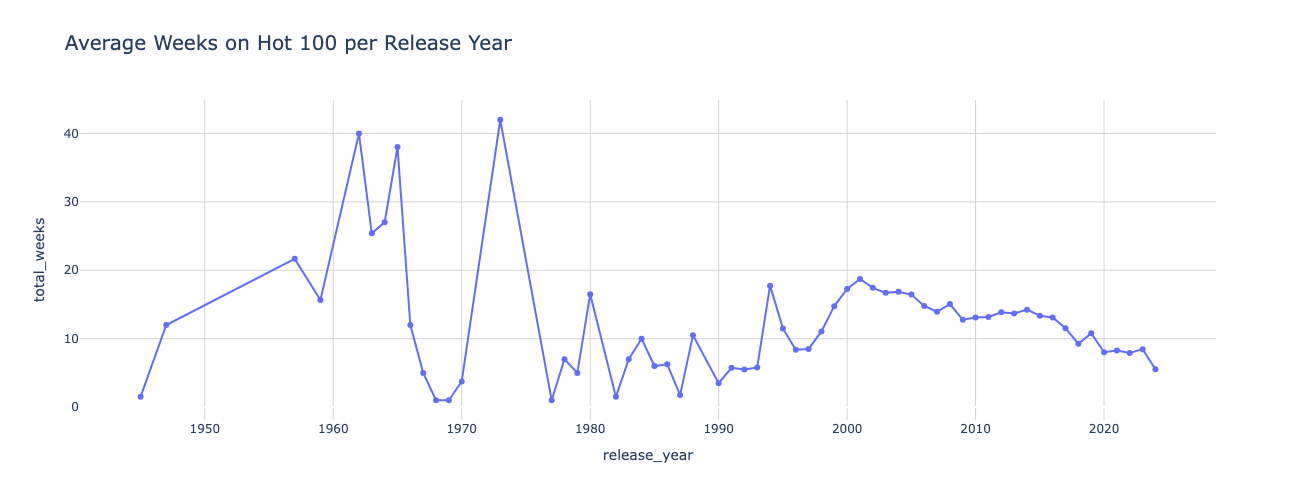

In [79]:
# Create line chart with markers and hover data
fig = px.line(
    avg_weeks_per_year,
    x='release_year',                  # x-axis: song release year
    y='total_weeks',                   # y-axis: average weeks on Hot 100
    markers=True,                      # show points on line
    title='Average Weeks on Hot 100 per Release Year',
    hover_data={'release_year': True, 'total_weeks': True}  # show values on hover
)

# Customize layout: size, background, grid, and title font
fig.update_layout(
    width=1200,                        # figure width
    height=500,                        # figure height
    plot_bgcolor='white',              # plot area background color
    paper_bgcolor='white',             # whole figure background
    title_font_size=20,                # title font size
    xaxis=dict(showgrid=True, gridcolor='lightgray'),  # x-axis grid style
    yaxis=dict(showgrid=True, gridcolor='lightgray')   # y-axis grid style
)

# Display interactive chart
fig.show()

#### 1.1. Average Chart Duration Insights

- Older songs often stayed on the Hot 100 **much longer**, e.g., 1962 → 40 weeks, 1973 → 42 weeks.  
- **Pre-streaming era (2000–2014):** average chart duration ~13–18 weeks.  
- **Streaming era (2015–2024):** songs rise and fall faster, with averages dropping to ~5–10 weeks.  
- This trend helps explain why some songs, even without reaching #1, can remain on the chart for **20+ weeks**, forming the pool of hidden longevity champions.

### 1.2 Peak Position Distribution
 
This analysis examines **where songs typically peak on the Hot 100**.  
While #1 hits get the headlines, many tracks achieve long-term popularity without ever reaching the top.

- Tracks are grouped by **peak position** (1 = top of the chart).  
- Distribution shows **how common #1 hits are** versus mid-chart tracks.  
- Helps identify **potential hidden longevity champions**, which often peak below #1.

In [52]:
# Distribution of peak positions across all tracks
peak_position_counts = track_metrics_layer1['peak_position'].value_counts().sort_index()
print("\nPeak position distribution:\n\n", peak_position_counts.head(), "\n")


Peak position distribution:

 peak_position
1    325
2    142
3    148
4    131
5    117
Name: count, dtype: Int64 



#### **Visual:** Distribution of Peak Positions Across All Tracks  

This interactive bar chart shows **how frequently tracks achieve each peak position** on the Hot 100.  
- The x-axis represents the **peak position** (1 = top of the chart).  
- The y-axis shows the **number of tracks** at each position.  
- Hover over bars to see exact counts per peak position.  
- Reveals that **most songs peak below #1**, highlighting the pool of potential hidden longevity champions.

In [53]:
# Convert to DataFrame for Plotly
peak_position_df = peak_position_counts.reset_index()
peak_position_df.columns = ['peak_position', 'num_tracks']

# Interactive bar chart
fig = px.bar(
    peak_position_df,
    x='peak_position',
    y='num_tracks',
    title='Distribution of Peak Positions Across All Tracks',
    labels={'peak_position':'Peak Position', 'num_tracks':'Number of Tracks'},
    hover_data={'peak_position': True, 'num_tracks': True}
)

# Update layout for size, background, and x-axis ticks
fig.update_layout(
    width=1200,
    height=500,
    plot_bgcolor='white',
    paper_bgcolor='white',
    title_font_size=20,
    xaxis=dict(
        showgrid=True,
        gridcolor='lightgray',
        tickmode='linear',   # linear spacing for ticks
        dtick=10             # tick every 10 units: 0,10,20,...
    ),
    yaxis=dict(showgrid=True, gridcolor='lightgray')
)

fig.show()

#### 1.2 Peak Position Distribution Insights

- Only **325 tracks** out of 10,783 ever reached **#1**, highlighting how rare top-charting songs are.  
- All other positions (#2–#100) have **fewer than 150 tracks each**, showing most songs peak in the mid-to-lower ranks.  
- Many **hidden longevity champions** peak **outside #1**, often in the **#2–#15 range**, allowing them to **accumulate weeks steadily** without topping the chart.  
- This demonstrates that **long-lasting success doesn’t require hitting #1**—consistency in mid-chart positions can create enduring hits.

### 1.3: Average Chart Duration Over Time (2000-2024)

This analysis focuses on **recent trends in chart longevity**:  

- Considers tracks released between **2000 and 2024**.  
- Calculates the **average number of weeks** each track remained on the Hot 100 per release year.  
- Highlights **differences between the pre-streaming (2000–2014) and streaming (2015–2024) eras**.  
- Helps identify whether songs are rising and falling faster in recent years, which affects the pool of hidden longevity champions.

In [54]:
# Focus on modern era: 2000-2024
avg_weeks_2000_2024 = (
    track_metrics_layer1[track_metrics_layer1['release_year'].between(2000, 2024)]
    .groupby('release_year')['total_weeks']
    .mean()
    .reset_index()
    .sort_values('release_year')
)

print("\nAvg chart duration (2000-2024):\n\n", avg_weeks_2000_2024.head(25), "\n")


Avg chart duration (2000-2024):

     release_year  total_weeks
0           2000    17.267782
1           2001     18.72549
2           2002    17.431734
3           2003    16.695971
4           2004     16.85098
5           2005    16.443452
6           2006    14.790274
7           2007    13.933131
8           2008    15.063037
9           2009    12.770349
10          2010    13.098253
11          2011    13.159737
12          2012     13.86514
13          2013    13.690217
14          2014    14.241558
15          2015    13.348485
16          2016    13.103064
17          2017    11.525532
18          2018     9.256667
19          2019    10.791411
20          2020     8.024133
21          2021     8.254844
22          2022     7.902439
23          2023     8.468563
24          2024     5.521739 



#### **Visual:** Average Chart Duration Over Time (2000-2024)

This interactive line chart shows how the **average chart duration of tracks** has changed in the modern era.  
- The x-axis represents the **track release year**.  
- The y-axis shows the **average number of weeks** a track stayed on the Hot 100.  
- Each marker represents a release year; hover over points to see the exact values.  
- Highlights differences between the **pre-streaming (2000–2014)** and **streaming (2015–2024)** eras.

In [55]:
# Interactive line chart for 2000-2024
fig = px.line(
    avg_weeks_2000_2024,
    x='release_year',
    y='total_weeks',
    markers=True,  # show points
    title='Average Weeks on Hot 100 per Release Year (2000–2024)',
    hover_data={'release_year': True, 'total_weeks': True}
)

# Layout styling for better visuals
fig.update_layout(
    width=1200,
    height=500,
    plot_bgcolor='white',
    paper_bgcolor='white',
    title_font_size=20,
    xaxis=dict(showgrid=True, gridcolor='lightgray', dtick=1),
    yaxis=dict(showgrid=True, gridcolor='lightgray')
)

fig.show()

#### 1.3 Average Chart Duration (2000–2024) Insights

- **Pre-streaming era (2000–2014):** tracks stayed on the Hot 100 for **~13–18 weeks** on average, indicating relatively slower rises and falls.  
- **Streaming era (2015–2024):** average duration drops to **~5–13 weeks**, showing songs climb and exit the charts faster.  
- The declining trend highlights why **modern hidden longevity champions** are rarer—they must sustain popularity despite faster chart turnover.  
- Peaks in 2001–2004 (~16–18 weeks) show that some early 2000s hits had extended staying power even before streaming reshaped chart dynamics.

### 1.4 #1 vs Non-#1 Tracks Per Year

This analysis examines **how many songs each year reached #1** versus those that **peaked below #1**:  

- Tracks are flagged as `#1 hits` if their **peak position = 1**, otherwise `Non-#1`.  
- Counts are aggregated **per release year** to observe trends over time.  
- Helps highlight the **rarity of #1 hits** and the **prevalence of long-lasting non-#1 tracks**—the pool from which hidden longevity champions emerge.  
- The first table shows **early years (2000–2009)**, while the second shows **recent years (2015–2024)**.

In [81]:
# Identify #1 hits
track_metrics_layer1['is_number_one'] = track_metrics_layer1['peak_position'] == 1

# Count #1 vs non-#1 tracks per year
num_1_vs_non1_per_year = (
    track_metrics_layer1
    .groupby('release_year')['is_number_one']
    .value_counts()
    .unstack(fill_value=0)
)

# Display the first 10 rows
print("Number of #1 vs Non-#1 Tracks (First 10 years):")
display(num_1_vs_non1_per_year.head(10))

# Display the last 10 rows
print("\nNumber of #1 vs Non-#1 Tracks (Most Recent 10 years):")
display(num_1_vs_non1_per_year.tail(10))

Number of #1 vs Non-#1 Tracks (First 10 years):


is_number_one,False,True
release_year,,
1945,2,0
1947,2,0
1957,3,0
1959,3,0
1962,1,0
1963,5,0
1964,1,1
1965,1,0
1966,1,0



Number of #1 vs Non-#1 Tracks (Most Recent 10 years):


is_number_one,False,True
release_year,,
2015,386,10
2016,348,11
2017,464,6
2018,589,11
2019,472,17
2020,642,21
2021,655,16
2022,601,14
2023,653,15


#### **Visual:** #1 vs Non-#1 Tracks Per Year

This interactive line chart illustrates the **annual distribution of #1 hits versus non-#1 tracks**:  

- The **line** shows the number of tracks that never reached #1 each year (Non-#1).  
- **Red markers** highlight tracks that **peaked at #1**.  
- Hover over points to see the exact counts for each year.  
- Highlights how **#1 hits are rare** compared to the many tracks that achieve moderate chart success, forming the pool for hidden longevity champions.  
- Shows trends across **pre-streaming (2000–2014)** and **streaming (2015–2024)** eras.

In [57]:
# Prepare data
df_1_vs_non1 = num_1_vs_non1_per_year.reset_index()

# Line chart: #1 vs Non-#1 tracks per year
fig = px.line(
    df_1_vs_non1,
    x='release_year',
    y=[False],            # False = Non-#1, True = #1 hits
    labels={
        'value': 'Number of Tracks',
        'release_year': 'Release Year',
        'variable': 'Track Type'
    },
    title='#1 vs Non-#1 Tracks per Year',
    markers=True                # show points
)

# Add #1 tracks as dots only
fig.add_scatter(
    x=df_1_vs_non1['release_year'],
    y=df_1_vs_non1[True],       # #1 tracks
    mode='markers',             # only dots
    name='#1 Tracks',
    marker=dict(color='red', size=8)
)

# Update layout for size and appearance
fig.update_layout(
    width=1200,
    height=500,
    plot_bgcolor='white',       # chart area background
    paper_bgcolor='white',      # entire figure background
    title_font_size=20,
    xaxis=dict(showgrid=True, gridcolor='lightgray'),
    yaxis=dict(showgrid=True, gridcolor='lightgray'),  # linear scale
    legend_title_text='Track Type'
)

# Show chart
fig.show()

#### 1.4 #1 vs non-#1 Tracks per Year Insights

- **#1 Hits Are Rare:** 1999 → 11 #1 vs 154 non-#1; 2020 → 21 #1 vs 642 non-#1.  
- **Non-#1 Tracks Dominate:** Most long-lasting songs never reach #1, forming hidden longevity champions.  
- **Charting Volume Grows Over Time:** Pre-2000: <20 tracks/year; Post-2000: hundreds/year (e.g., 2021 → 655 non-#1).  
- **#1 Tracks Fairly Constant:** ~10–25 per year despite growth in total chart entries.  
- **Takeaway:** Longevity is often independent of peak position.

### 1.5: Chart Longevity by Era

This analysis compares **average chart duration between music eras**:  

- Tracks are grouped into **two eras**:  
  - **Pre-streaming (≤2014)**  
  - **Streaming (≥2015)**  
- Calculates the **average number of weeks** tracks stayed on the Hot 100 in each era.  
- Helps show how the **rise of streaming** has affected chart longevity and the environment for hidden longevity champions.

In [83]:
# Assign era (pre-streaming <=2014, streaming >=2015)
track_metrics_layer1['era'] = track_metrics_layer1['release_year'].apply(
    lambda x: 'pre-streaming' if x <= 2014 else 'streaming'
)

avg_weeks_by_era = (
    track_metrics_layer1
    .groupby('era')['total_weeks']
    .mean()
)
print("Avg weeks by era:\n", avg_weeks_by_era, "\n")

Avg weeks by era:
 era
pre-streaming    14.798722
streaming         9.256866
Name: total_weeks, dtype: Float64 



#### Average Weeks on Chart by Era

| Era            | Average Weeks |
|----------------|---------------|
| Pre-Streaming  | 14.8          |
| Streaming      | 9.3           |

#### 1.5 Chart Longevity by Era Insight:
- Songs in the **pre-streaming era** stayed on the charts **longer on average** than in the streaming era.
- Possible reasons:
  1. **Faster turnover now:** Streaming leads to quicker peaks and declines in popularity.
  2. **More variety and access:** Listeners can explore more songs, so hits face stiffer competition.
  3. **Chart methodology changes:** Streaming metrics may shorten chart longevity compared to sales and radio.
  
**Key takeaway:**  
The streaming era favors **short-term popularity bursts** rather than sustained chart dominance.

### Layer 1: Takeaway – Broad Trends

The Hot 100 shows that **long-lasting chart success is rare** and not dependent on hitting #1.  

- Most songs peak below the top spot, yet some **accumulate weeks steadily**, forming the pool of hidden longevity champions.  
- **Chart longevity has declined** in the streaming era: tracks rise and fall faster, and average weeks on the Hot 100 have dropped.  
- Pre-streaming hits had more extended runs, giving songs more opportunity to build audience connection.  
- Despite methodological changes and faster consumption, **mid-chart consistency** continues to be a key driver of enduring success.  

**Bottom line:** Hidden longevity champions emerge from **steady performance rather than peak glory**, and their stories are shaped by the evolving dynamics of music consumption over the last 25 years.

## Layer 2: Segment Patterns (Middle)

Building on the broad trends from Layer 1, this layer explores **what drives long-term chart success**.  
We focus on **hidden longevity champions** — songs that never reach #1 but **remain on the Hot 100 for 20+ weeks**.  

This layer examines the **musical, structural, and contextual patterns** that set these enduring tracks apart from typical chart entries.  

Key questions driving the analysis:  
1. Which tracks **qualify as hidden longevity champions**?  
2. Do hidden champions share common **audio features** (danceability, energy, tempo, valence, acousticness)?  
3. Are hidden champions more often **explicit or clean**?  
4. Are they **solo tracks or collaborations**?  
5. Are certain **album types** more likely to produce hidden champions?  
6. Do hidden champions **peak in particular months or seasons**?  

By answering these questions, we uncover the **characteristics and strategies** that help songs achieve sustained chart presence.

### 2.1 Hidden Longevity Champions

Hidden longevity champions are defined as **songs that never reached #1 but stayed on the Hot 100 for 20+ weeks**.  

This step identifies the core set of tracks that form the foundation for further analysis in Layer 2.  

**Key points explored in this section:**
- Total number of unique hidden longevity champions
- Distribution of peak positions
- Era breakdown (pre-streaming vs. streaming)
- Top 20 longest-charting hidden champions

In [59]:
# Filter Layer 2 data for hidden longevity champions
hidden_longevity_champs = (
    track_metrics_layer2[
        (track_metrics_layer2['total_weeks'] >= 20) &
        (track_metrics_layer2['peak_position'] > 1)
    ]
    .drop_duplicates(subset=['track_id'])  # ensure unique tracks
    .copy()
)

# Number of unique hidden champions
num_hidden_champs = hidden_longevity_champs.shape[0]

# Count of tracks by peak position (top 10 for overview)
peak_counts = hidden_longevity_champs['peak_position'].value_counts().sort_index().head(10)

# Assign era: pre-streaming <=2014, streaming >=2015
hidden_longevity_champs['era'] = hidden_longevity_champs['release_year'].apply(
    lambda x: 'pre-streaming' if x <= 2014 else 'streaming'
)

# Count number of hidden longevity champions by era
era_counts = hidden_longevity_champs['era'].value_counts()

# Top 20 hidden champions by total_weeks
top_hidden_champs = hidden_longevity_champs.sort_values(
    by='total_weeks', ascending=False
)[['track_name', 'total_weeks', 'peak_position', 'release_year']].head(20)

# Print summary
print(f"\nNumber of unique hidden longevity champion tracks: {num_hidden_champs}")
print("\nCount of tracks by peak position (top 10):\n", peak_counts)
print("\nNumber of hidden longevity champions by era:\n", era_counts)
print("\nTop 20 Hidden Longevity Champions:\n", top_hidden_champs)


Number of unique hidden longevity champion tracks: 2973

Count of tracks by peak position (top 10):
 peak_position
2     128
3     129
4     109
5      97
6      99
7     103
8      83
9      70
10     73
11     81
Name: count, dtype: Int64

Number of hidden longevity champions by era:
 era
pre-streaming    1982
streaming         991
Name: count, dtype: int64

Top 20 Hidden Longevity Champions:
                          track_name  total_weeks  peak_position  release_year
0   1, 2 Step (feat. Missy Elliott)          109              2          2004
3                       Radioactive           87              3          2012
2                You Belong With Me           87              2          2008
4                              Sail           79             17          2011
5                         I'm Yours           76              6          2008
6                            Snooze           70              2          2022
7                    Counting Stars           68      

#### **Visual:** Top 100 Hidden Longevity Champions – Weeks vs Peak Position

This scatter plot highlights the **longest-charting non-#1 songs**:

- **X-axis:** Peak chart position (1 = best; reversed so lower numbers are left).  
- **Y-axis:** Total weeks on the Hot 100.  
- **Bubble size:** Corresponds to total weeks, emphasizing the longest-charting tracks.  
- **Color:** Indicates the song’s release year.  
- Hover over a bubble to see the **track name, release year, total weeks, and peak position**.  

The chart shows that hidden longevity champions often peak **outside #1**, yet accumulate **20–50+ weeks** on the chart, demonstrating sustained popularity without topping the chart.

In [60]:
# Prepare top 100 hidden longevity champions
top100_champs = hidden_longevity_champs.sort_values(
    by='total_weeks', ascending=False
).head(100)

# Scatter plot: total_weeks vs peak_position
fig = px.scatter(
    top100_champs,
    x='peak_position',  # better rank on the left (lower number = better)
    y='total_weeks',
    size='total_weeks',  # bubble size by total weeks
    color='release_year',  # color by release year
    hover_data=['track_name', 'release_year', 'total_weeks', 'peak_position'],
    title='Top 100 Hidden Longevity Champions: Weeks vs Peak Position',
    labels={
        'peak_position': 'Peak Position',
        'total_weeks': 'Weeks on Chart',
        'release_year': 'Release Year'
    },
    height=500
)

# Reverse x-axis so best peak (1) is on left
fig.update_xaxes(autorange='reversed')

# Show figure
fig.show()

#### 2.1 Hidden Longevity Champions Insights

- **2,973 unique tracks** never reached #1 but stayed on the charts for **20+ weeks**.  
- About **67%** of these hidden champions are from the **pre-streaming era**, while some **streaming-era** tracks also demonstrate impressive chart endurance.  
- **Peak positions** are most commonly **#2 or #3**, showing that consistent mid-top performance can build long-term success.  
- These tracks demonstrate that **longevity doesn’t require hitting #1**, but relies on **steady audience engagement**.

**Key Takeaway:**  
Longevity on the Hot 100 is **not dependent on reaching #1**. Many tracks sustain long-term popularity by consistently charting in the **#2–#5 range**, with the majority of hidden champions coming from the **pre-streaming era**, though notable streaming-era tracks also achieve extended chart runs.

### 2.2 Audio Features of Hidden Longevity Champions

This section explores whether hidden longevity champions share **common musical characteristics**.  

- We focus on **danceability, energy, tempo, valence, acousticness**, and other audio features.  
- The goal is to identify patterns that may contribute to a track's **sustained popularity**, even without hitting #1.  
- Descriptive statistics provide a **summary of typical ranges** for long-lasting tracks.

In [61]:
# Select only audio feature columns
audio_feature_cols = [
    'danceability', 'energy', 'key', 'loudness', 'mode',
    'speechiness', 'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo', 'time_signature'
]
# Compute descriptive statistics
audio_features_summary = hidden_longevity_champs[audio_feature_cols].describe().T

print("Summary of Audio Features for Hidden Longevity Champions:")
audio_features_summary

Summary of Audio Features for Hidden Longevity Champions:


,count,mean,std,min,25%,50%,75%,max
danceability,2972.0,0.643092,0.141200,0.000000,0.548000,0.64500,0.743250,0.971
energy,2972.0,0.680528,0.164204,0.003970,0.571000,0.69450,0.807000,0.999
loudness,2972.0,-5.996797,2.216982,-25.694000,-7.137000,-5.65600,-4.495250,-1.299
speechiness,2972.0,0.094490,0.098437,0.000000,0.034700,0.05045,0.106000,0.951
acousticness,2972.0,0.165237,0.201569,0.000007,0.019675,0.07985,0.238250,0.978
instrumentalness,2972.0,0.021659,0.121329,0.000000,0.000000,0.00000,0.000021,0.966
liveness,2972.0,0.176068,0.131935,0.000000,0.093300,0.12300,0.226000,0.963
valence,2972.0,0.525105,0.222123,0.000000,0.353750,0.52700,0.699000,0.976
tempo,2972.0,121.582260,29.167750,0.000000,97.441250,120.12300,140.962250,210.893


#### Visual: Audio Feature Distribution by Era

**Explore how hidden longevity champions differ musically across eras:**

- **Era Split:** Pre-streaming (≤2014) vs. Streaming (≥2015)  
- **Features Shown:** ***Danceability, Energy, Speechiness, Acousticness, Instrumentalness, Liveness, Valence***  
- **Box Plot Insight:** Median, interquartile range, and outliers reveal typical and extreme feature values

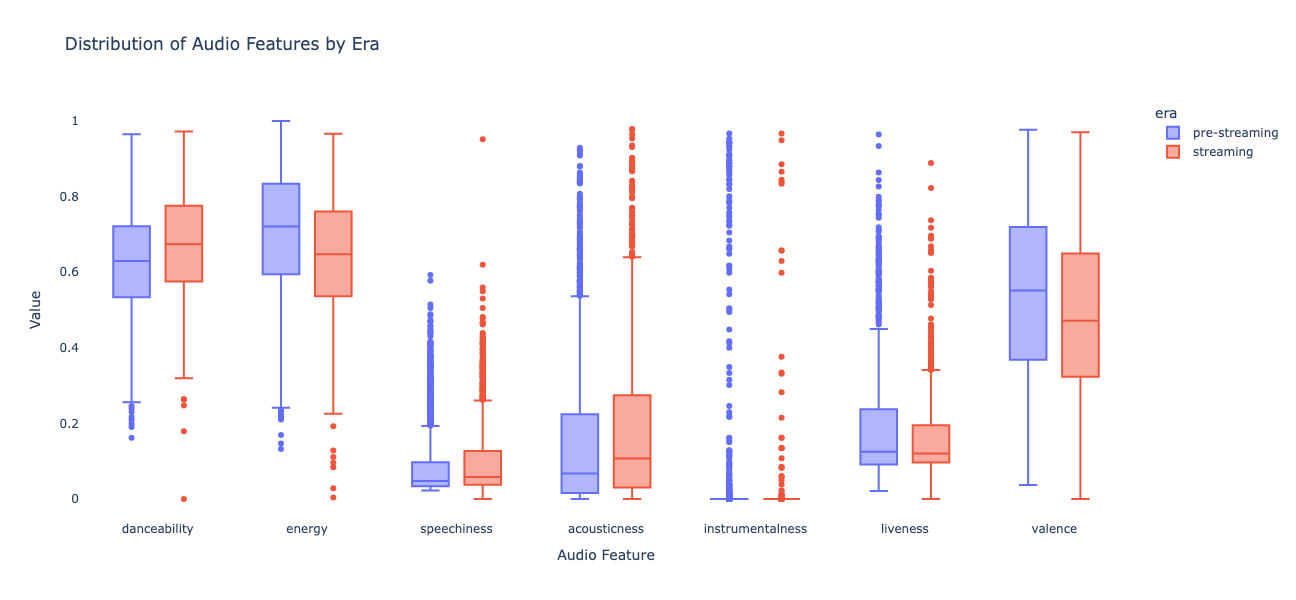

In [90]:
# Features to visualize
viz_features = [
    'danceability', 'energy',  'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence'
]

# Ensure 'era' exists in the dataframe
hidden_longevity_champs['era'] = hidden_longevity_champs['release_year'].apply(
    lambda x: 'pre-streaming' if x <= 2014 else 'streaming'
)

# Melt dataframe for easier plotting
df_melted = hidden_longevity_champs.melt(
    id_vars='era',
    value_vars=viz_features,
    var_name='Audio Feature',
    value_name='Value'
)

# Box plot of audio features by era
fig = px.box(
    df_melted,
    x='Audio Feature',
    y='Value',
    color='era',
    title='Distribution of Audio Features by Era',
    width=1200,
    height=600
)

fig.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig.show()

#### 2.2 Audio Features Insights

- **Danceable & Energetic:** Hidden champions are moderately danceable (0.64) and energetic (0.68), supporting broad listener appeal.  
- **Valence:** Emotional tone is balanced (0.53), meaning hits are neither overly happy nor sad.  
- **Acoustic & Instrumental:** Mostly vocal tracks (low instrumentalness 0.02, acousticness 0.17).  
- **Tempo:** Average tempo ~122 BPM, ideal for radio/streaming play.  
- **Consistency:** These characteristics suggest hidden champions maintain a **sonically accessible profile**, helping them sustain long-term audience engagement.

**Key Takeaway:**  
Hidden longevity champions generally exhibit **moderate energy, danceability, and tempo**, with balanced emotional tone, making them broadly appealing. Their musical accessibility likely contributes to their ability to remain on the Hot 100 for extended periods without ever reaching #1.

### 2.3 Explicit vs Clean Tracks

This analysis checks **whether hidden champions are more often explicit or clean**.  

- Column used: `explicit`.  
- Counts the number of explicit vs clean tracks to identify trends in lyrical content.  

In [ ]:
# Explicit vs Clean Tracks
explicit_counts = hidden_longevity_champs['explicit'].value_counts()
explicit_percent = hidden_longevity_champs['explicit'].value_counts(normalize=True) * 100

print("Explicit vs Clean Counts:")
print(explicit_counts)
print("\nPercentage:")
print(explicit_percent)

#### 2.3 Explicit vs Clean Tracks Insights

- **Majority Clean:** ~73% of the 2,973 hidden longevity champions are **clean**, while ~27% are explicit  
- **Audience-Friendly:** Clean tracks are more **radio- and playlist-friendly**, reaching wider audiences  
- **Longevity Factor:** Prevalence of clean tracks suggests **accessible lyrical content supports long-term chart presence**  

**Key Takeaway:** Hidden longevity champions tend to be **clean and broadly appealing**, showing that **lyrical accessibility**, rather than edginess, helps sustain long-term popularity.

### 2.4 Album Type Distribution

This analysis examines **which album types produce hidden champions**.  

- Column used: `album_type`.  
- Counts distribution of hidden champions across album types (e.g., album, single, EP). 

In [ ]:
album_type_counts = hidden_longevity_champs['album_type'].value_counts()
album_type_percent = hidden_longevity_champs['album_type'].value_counts(normalize=True) * 100

print("Hidden Champions by Album Type:")
print(album_type_counts)
print("\nPercentage:")
print(album_type_percent)

#### 2.4 Album Type Distribution Insights

- **Full albums:** ~84%  
- **Singles:** ~12%  
- **Compilations:** ~3.5%  

**Key Takeaway:** Tracks from **full albums** are more likely to sustain long-term chart presence, suggesting that **album context** supports hidden longevity better than standalone releases.

### 2.5 Track Duration Analysis

This analysis investigates **the typical duration of hidden champions**.  

- Column used: `duration_min`.  
- Descriptive statistics (mean, median, min, max) are computed to understand if longer or shorter tracks dominate.  

In [ ]:
duration_stats = hidden_longevity_champs['duration_min'].describe()

print("Track Duration Statistics for Hidden Longevity Champions (minutes):")
duration_stats

#### 2.5 Track Duration Insights

- **Average duration:** ~3.8 minutes  
- **Typical range:** 3.3–4.1 minutes  

**Key Takeaway:** Hidden longevity champions are mostly **medium-length songs**, suggesting that this duration balances **listener engagement and replayability**, supporting long-term chart presence.

### 2.6 Seasonal / Monthly Patterns

This analysis looks at **whether hidden champions tend to peak in particular months or seasons**.  

- Column used: `first_chart_week`.  
- Extracts the month and counts the number of tracks first appearing in each month.  

In [ ]:
# Extract peak week
hidden_longevity_champs['peak_week'] = hidden_longevity_champs['first_chart_week']

# Extract month and season
hidden_longevity_champs['peak_month'] = hidden_longevity_champs['peak_week'].dt.month
hidden_longevity_champs['peak_season'] = pd.cut(
    hidden_longevity_champs['peak_month'],
    bins=[0,3,6,9,12],
    labels=['Winter','Spring','Summer','Fall'],
    right=True
)

# Count by season
season_counts = hidden_longevity_champs['peak_season'].value_counts()
season_percent = hidden_longevity_champs['peak_season'].value_counts(normalize=True) * 100

print("Hidden Champions Peak by Season:")
print(season_counts)
print("\nPercentage:")
print(season_percent)

#### 2.6 Seasonal / Monthly Patterns Insights

- **Peak distribution:** Fairly even throughout the year  
- **Slightly higher peaks:** Spring (26%) and Fall (26%)  

**Key Takeaway:** Hidden longevity champions show **no strong seasonal dependence**, indicating that **chart longevity is largely independent of release timing**.

### Layer 2: Takeaway - Segment Patterns

Hidden longevity champions—tracks that never reach #1 but remain on the Hot 100 for 20+ weeks—follow distinct patterns that support long-term success.  

- Most tracks are from **full albums** (84%) and are **clean** (73%), making them broadly accessible for radio and playlists.  
- **Medium-length songs** (~3.8 min) with **moderate danceability, energy, and tempo** dominate, balancing engagement and replayability.  
- **Peak positions** usually sit at #2–#3, showing that **steady mid-chart performance** drives longevity more than instant hits.  
- Hidden champions span both **pre-streaming and streaming eras**, and **seasonal timing has minimal effect**, though Spring and Fall see slight peaks (~26% each).  

**Bottom line:** Long-term chart presence is fueled by **accessible lyrics, broadly appealing musical traits, album context, and consistent audience engagement**, rather than peak positions or seasonal release timing.

## Layer 3: Spotlight the Heroes (Top)

This layer highlights the **standout tracks and artists** — the true "hidden champions" of the Hot 100.  

Key questions include:  
- Which hidden champions stayed on the chart the **longest**?  
- Which artists have the **most hidden longevity champions**?  
- Did any tracks **re-chart years later**?
- Are there **“sleeper hits”** that peaked modestly but lasted a long time?  

This layer is **storytelling-focused**, showcasing specific songs and artists that define long-term chart success, bringing the analysis to life.

### 3.1 Longest-Charting Hidden Champions

This section highlights the **hidden champions that stayed on the Hot 100 the longest** without ever reaching #1. By focusing on tracks with **total weeks ≥20 and peak positions between #2 and #10**, we uncover songs that achieved **sustained audience engagement over time**.  

Here, we explore:  
- Which tracks dominated the charts in terms of **total weeks**  
- How **single-artist vs. multi-artist collaborations** perform  
- The **artists behind these enduring hits**  

The goal is to **spotlight the tracks and performers that quietly built lasting impact**, revealing patterns behind **long-term chart resilience**.

In [96]:
# Filter Layer 3 for hidden longevity champions
# Conditions: total_weeks >= 20, peak_position 2–10
longest_charting_hidden = track_metrics_layer3[
    (track_metrics_layer3['total_weeks'] >= 20) &
    (track_metrics_layer3['peak_position'] >= 2) &
    (track_metrics_layer3['peak_position'] <= 10)
].drop_duplicates(subset=['track_id']).copy()

# Rank by total weeks
longest_charting_hidden = longest_charting_hidden.sort_values(by='total_weeks', ascending=False)

# Explode once for artist-level analysis
longest_charting_exploded = longest_charting_hidden.explode(['artist_id','name','popularity','followers'])

# Total number of longest-charting hidden tracks
num_tracks = len(longest_charting_hidden)
print(f"Total longest-charting hidden tracks: {num_tracks}\n")

# Single vs multi-artist counts
multi_artist_counts = longest_charting_hidden['multi_artist'].value_counts()
print("Multi-artist vs Single-artist tracks:\n", multi_artist_counts, "\n")

num_unique_artists = longest_charting_exploded['name'].nunique()
print(f"Number of unique artists across these tracks: {num_unique_artists}\n")

# Top 50 longest-charting hidden tracks
top_50_tracks = longest_charting_hidden[
    ['track_name','total_weeks','peak_position','release_year','multi_artist','name','popularity','followers']
].head(50)

print("Top 50 Longest-Charting Hidden Champions:")
display(top_50_tracks)

Total longest-charting hidden tracks: 891

Multi-artist vs Single-artist tracks:
 multi_artist
False    626
True     265
Name: count, dtype: int64 

Number of unique artists across these tracks: 588

Top 50 Longest-Charting Hidden Champions:


,track_name,total_weeks,peak_position,release_year,multi_artist,name,popularity,followers
2928,"1, 2 Step (feat. Missy Elliott)",109,2,2004,True,"[Ciara, Missy Elliott]","[72, 72]","[6741121, 2543992]"
1238,You Belong With Me,87,2,2008,False,[Taylor Swift],[100],[123544806]
1604,Radioactive,87,3,2012,False,[Imagine Dragons],[89],[54853599]
500,I'm Yours,76,6,2008,False,[Jason Mraz],[73],[7238795]
1770,Snooze,70,2,2022,False,[SZA],[90],[23627089]
2612,Counting Stars,68,2,2014,False,[OneRepublic],[85],[17522655]
1341,Something in the Orange,66,10,2022,False,[Zach Bryan],[91],[5274397]
1611,"Hey, Soul Sister",65,3,2010,False,[Train],[76],[4322013]
239,Before He Cheats,64,8,2005,False,[Carrie Underwood],[72],[5998552]
2050,You Proof,62,5,2023,False,[Morgan Wallen],[91],[10845945]


#### Visual: Popularity Distribution of Longest-Charting Hidden Champions

This histogram (with an overlaid boxplot) shows the **popularity scores of artists** behind the longest-charting hidden champions.

- **X-axis:** Artist popularity score  
- **Y-axis:** Number of tracks  
- **Distribution:** Most tracks are created by artists with **moderate to high popularity**, though some lesser-known artists also appear  
- **Boxplot overlay:** Highlights the **median, interquartile range, and outliers** for popularity  

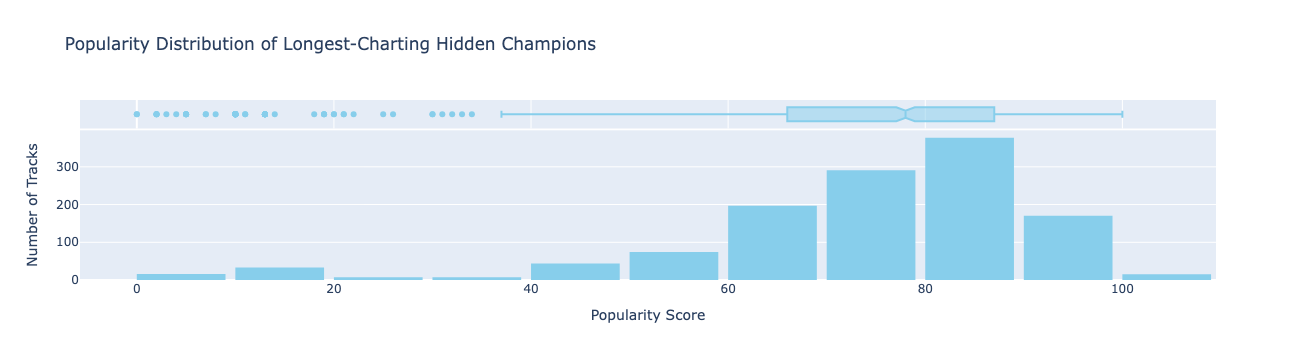

In [98]:
# Popularity Distribution (Artist-Level)

# Create histogram with boxplot overlay
fig = px.histogram(
    longest_charting_exploded,
    x='popularity',
    nbins=20,
    marginal='box',   # adds a boxplot on top
    color_discrete_sequence=['skyblue'],
    title='Popularity Distribution of Longest-Charting Hidden Champions',
    labels={'popularity':'Popularity Score', 'count':'Number of Tracks'}
)
fig.update_layout(
    xaxis_title='Popularity Score',
    yaxis_title='Number of Tracks',
    bargap=0.1
)
fig.show()

#### 3.1 Longest-Charting Hidden Champions – Insight & Key Takeaway

- **Total tracks:** 891 (20+ weeks on chart, peak #2–#10)  
- **Multi-artist vs single-artist:** 265 (30%) multi-artist, 626 (70%) single-artist  
- **Unique artists:** 588  

**Insight:**  
Most longest-charting hidden champions are **single-artist tracks** with **moderate to high popularity**, including both **classic and modern hits**. Multi-artist tracks are less common.  

**Key Takeaway:**  
**Chart longevity is driven by consistent audience engagement** rather than peak chart position, highlighting the value of tracks that steadily resonate with listeners over time.

### 3.2 Artists with Most Hidden Champions

This section spotlights the **performers behind the longest-charting hidden champions**, highlighting which artists consistently produce tracks that remain on the Hot 100 for extended periods.  

Here, we explore:  
- **Top artists** with the highest number of hidden longevity champions  
- How **average popularity and follower counts** relate to chart endurance  
- Notable **outliers** who achieve longevity despite modest popularity  

**Focus:** By examining the artists themselves, we can uncover patterns in **consistent audience engagement, fanbase strength, and track output** that contribute to long-term chart success. 

In [100]:
# 3.2 Artists with Most Hidden Champions (with popularity & followers)

# Group by artist to count number of hidden longevity champions
artist_champ_counts = longest_charting_exploded.groupby(
    ['artist_id', 'name']
).size().reset_index(name='num_hidden_champs')

# Compute average popularity and followers per artist
artist_metrics = longest_charting_exploded.groupby('name').agg({
    'popularity': 'mean',
    'followers': 'mean'
}).reset_index()

# Merge counts with metrics
top_artists = artist_champ_counts.merge(artist_metrics, on='name', how='left')

# Sort descending by number of hidden champions and get Top 20
top_artists = top_artists.sort_values(by='num_hidden_champs', ascending=False).head(20)

# Display Top Artists with hidden longevity champions, popularity, and followers
print("Top Artists with Most Hidden Longevity Champions:")
display(top_artists[['name', 'num_hidden_champs', 'popularity', 'followers']])

Top Artists with Most Hidden Longevity Champions:


,name,num_hidden_champs,popularity,followers
239,Drake,30,96.0,92537455.0
5,Taylor Swift,15,100.0,123544806.0
364,Lil Wayne,14,87.0,15375613.0
57,Nicki Minaj,14,87.0,32494337.0
459,DJ Cover This,14,10.0,695.0
550,Chris Brown,13,88.0,23634679.0
414,Rihanna,12,92.0,63115308.0
262,JAY-Z,11,85.0,9478189.0
99,P!nk,11,82.0,17190703.0
4,Maroon 5,11,87.0,42858633.0


#### Visual: Top Artists with Hidden Longevity Champions

This bubble chart highlights the **artists behind the most hidden longevity champions**:

- **X-axis:** Artist name  
- **Y-axis:** Average popularity score  
- **Bubble size:** Number of hidden longevity champions  
- **Bubble color:** Average follower count (Viridis scale)  

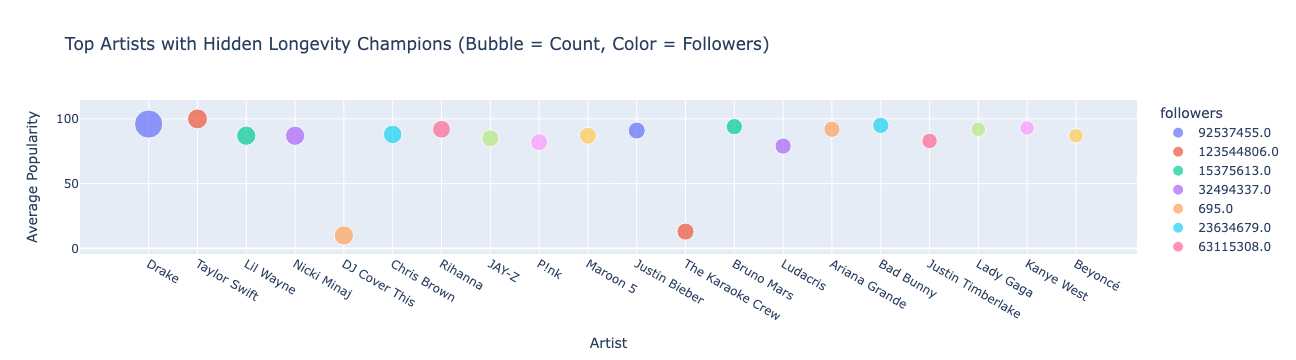

In [102]:
# Plot Bubble Chart
fig = px.scatter(
    top_artists,
    x='name',                      # Artist names on X-axis
    y='popularity',                # Average popularity on Y-axis
    size='num_hidden_champs',      # Bubble size = number of hidden champions
    color='followers',             # Bubble color = average followers
    color_continuous_scale='Viridis',
    title='Top Artists with Hidden Longevity Champions (Bubble = Count, Color = Followers)',
)

# Axis labels
fig.update_layout(
    xaxis_title='Artist',
    yaxis_title='Average Popularity',
)

fig.show()

#### 3.2 Artists with Most Hidden Champions – Insight & Key Takeaway

- **Top artist:** Drake (30 hidden champions)  
- **Next:** Taylor Swift (15)  
- **Notable niche performers:** DJ Cover This (14), The Karaoke Crew (11)  

**Insight:**  
Artists with the most hidden champions are generally **popular and widely followed**, but some niche performers also maintain multiple long-charting tracks.  

**Key Takeaway:**  
**Sustained chart presence depends on consistent output, audience engagement, and broad appeal**, showing that longevity is not solely tied to peak hits or mainstream fame.

### 3.3 Re-Charting / Chart Span Analysis

This section examines tracks that **re-charted or maintained exceptionally long chart spans**, highlighting songs that remain relevant over years.  

Key points explored include:  
- **Tracks with chart spans ≥1 year**, showing sustained audience engagement  
- How **holiday classics and perennial hits** reappear on the Hot 100  
- The relationship between **popularity, followers, and longevity**  

**Focus:** By analyzing chart span and re-charting patterns, we identify tracks that **consistently resonate with listeners** beyond their initial release window, revealing the drivers of enduring Hot 100 presence.

In [103]:
# 3.3 Re-Charting / Chart Span Analysis

# Tracks that re-charted (chart span >= 52 weeks)
recharted_tracks = longest_charting_exploded[longest_charting_exploded['chart_span_weeks'] >= 52].copy()

# Add chart span in years (rounded to 1 decimal)
recharted_tracks['chart_span_years'] = (recharted_tracks['chart_span_weeks'] / 52).round(1)

# Select relevant columns for display
final_display = recharted_tracks[[
    'track_name',
    'name',                    # artist name
    'first_chart_week',
    'last_chart_week',
    'chart_span_years',
    'popularity',
    'followers'
]]

# Number of tracks with chart span >= 1 year
num_long_chart_tracks = final_display['track_name'].nunique()
print(f"Number of Tracks with Chart Span >= 1 year: {num_long_chart_tracks}\n")

# Preview top 50
final_display.sort_values(by='chart_span_years', ascending=False).head(50)

Number of Tracks with Chart Span >= 1 year: 98



,track_name,name,first_chart_week,last_chart_week,chart_span_years,popularity,followers
2265,Bye Bye Bye - From Deadpool and Wolverine Soun...,*NSYNC,2000-01-29,2024-08-17,24.6,78,2662798
1649,The Christmas Song (Merry Christmas To You),Nat King Cole,2000-01-01,2024-01-06,24.1,71,2312641
899,Peaches & Eggplants (feat. 21 Savage),Young Nudy,2001-04-14,2023-10-28,22.6,70,1526537
899,Peaches & Eggplants (feat. 21 Savage),21 Savage,2001-04-14,2023-10-28,22.6,89,20281743
1696,Oh Boy,Cam'ron,2002-04-20,2024-04-20,22.1,60,739513
1696,Oh Boy,Juelz Santana,2002-04-20,2024-04-20,22.1,65,843688
2403,Suga Suga,Baby Bash,2003-08-23,2022-05-14,18.8,63,964771
2403,Suga Suga,Frankie J,2003-08-23,2022-05-14,18.8,60,623028
2875,Without Me,Eminem,2002-05-11,2020-02-01,17.8,93,91487128
1238,You Belong With Me,Taylor Swift,2004-09-18,2022-01-22,17.4,100,123544806


#### Visual: Tracks by Chart Span (Years)

This scatter plot highlights the **top 50 longest-charting hidden champions**, showing which tracks have maintained Hot 100 presence for the longest time.

- **X-axis:** Artist name  
- **Y-axis:** Chart span in years  
- **Bubble size:** Chart span in years  
- **Bubble color:** Track popularity (Viridis scale)  
- **Hover info:** Track name 

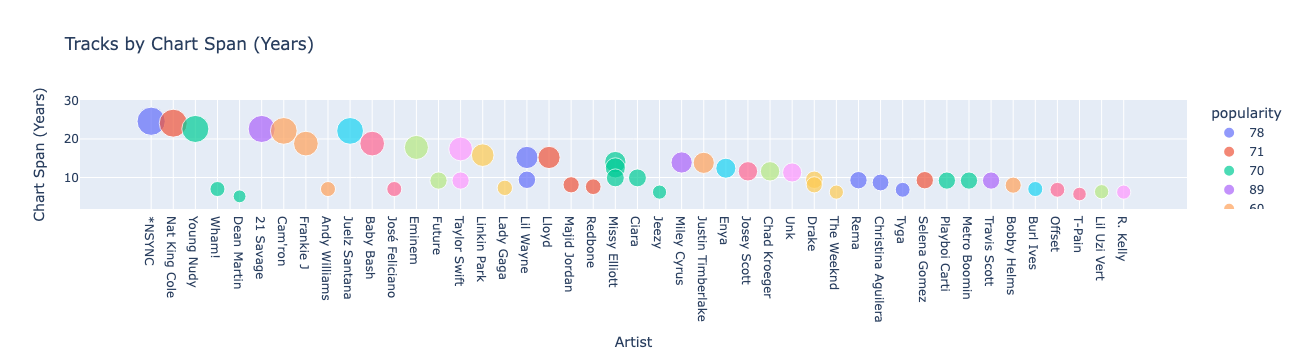

In [104]:
top_chart_span = final_display.sort_values(by='chart_span_years', ascending=False).head(50)

fig = px.scatter(
    top_chart_span,
    x='name',
    y='chart_span_years',
    size='chart_span_years',
    color='popularity',
    hover_data=['track_name'],
    color_continuous_scale='Viridis',
    title='Tracks by Chart Span (Years)'
)

fig.update_layout(
    xaxis_title='Artist',
    yaxis_title='Chart Span (Years)'
)
fig.show()

#### 3.3 Re-Charting / Chart Span Analysis – Insight & Key Takeaway

- **Longest-lasting tracks:** Bye Bye Bye, The Christmas Song >24 yrs; some 2000s hits >15 yrs  
- **Popularity vs longevity:** High popularity helps (Taylor Swift ~17–9 yrs), but moderate hits also endure  
- **Repeat artists:** Missy Elliott, Drake, Lil Wayne, Taylor Swift maintain multiple long-charting tracks (9–14 yrs)  
- **Holiday/Evergreen tracks:** Reappear annually (Feliz Navidad, Last Christmas)  

**Insight:**  
Re-charting tracks demonstrate that **timeless appeal, repeat artist output, and seasonal resurgence** extend chart longevity beyond initial release.  

**Key Takeaway:**  
**Consistent engagement and perennial relevance**—rather than peak position alone—drive long-term Hot 100 presence, highlighting the strategies behind enduring hits.

### 3.4 Top 50 Sleeper Hits (Long Duration, Modest Peak)

This section highlights tracks that **lasted a long time on the Hot 100 despite modest peak positions**, often achieving “sleeper hit” status.  

Key points explored include:  
- Tracks with **high total weeks but peaks outside #1**, showing steady engagement over instant stardom  
- **Sleeper score:** Total weeks divided by peak position, identifying tracks with the best **duration relative to peak**  
- Artists who **consistently produce sleeper hits**, and notable **lesser-known performers**  

**Focus:** Sleeper hits reveal how **longevity and broad audience appeal** can create enduring chart presence, even without topping the Hot 100.

In [107]:
# Compute a sleeper score: longer duration + modest peak
longest_charting_hidden['sleeper_score'] = longest_charting_hidden['total_weeks'] / longest_charting_hidden['peak_position']

# Sort descending by sleeper_score to get the top sleeper hits
top_sleepers = longest_charting_hidden.sort_values('sleeper_score', ascending=False)

# Optional: merge artist info if needed (exploded version)
top_sleepers_exploded = top_sleepers.explode(['artist_id', 'name', 'popularity', 'followers'])

# Select relevant columns for display
final_sleepers_display = top_sleepers_exploded[[
    'track_name',
    'name',                # artist
    'total_weeks',
    'peak_position',
    'sleeper_score',
    'popularity',
    'followers'
]]

# Preview top 50 sleeper hits
print("Top 50 Sleeper Hits (Long Duration, Modest Peak):")
display(final_sleepers_display.head(50))

Top 50 Sleeper Hits (Long Duration, Modest Peak):


,track_name,name,total_weeks,peak_position,sleeper_score,popularity,followers
2928,"1, 2 Step (feat. Missy Elliott)",Ciara,109,2,54.5,72,6741121
2928,"1, 2 Step (feat. Missy Elliott)",Missy Elliott,109,2,54.5,72,2543992
1238,You Belong With Me,Taylor Swift,87,2,43.5,100,123544806
1770,Snooze,SZA,70,2,35.0,90,23627089
2612,Counting Stars,OneRepublic,68,2,34.0,85,17522655
1825,Mirrors,Justin Timberlake,60,2,30.0,83,14594071
418,Need You Now,Lady A,60,2,30.0,67,3691970
1167,Thinking out Loud,Ed Sheeran,58,2,29.0,89,116502914
1604,Radioactive,Imagine Dragons,87,3,29.0,89,54853599
423,Lights,Ellie Goulding,57,2,28.5,80,12592500


#### 3.4 Visual: Top Sleeper Hits – Long Duration, Modest Peak

This bubble chart highlights the **top 50 sleeper hits** — tracks that stayed on the Hot 100 for a long time despite modest peak positions.

- **X-axis:** Artist name  
- **Y-axis:** Total weeks on chart  
- **Bubble size:** Artist popularity  
- **Bubble color:** Peak position (darker = better peak)  
- **Hover info:** Track name, sleeper score, popularity, followers  

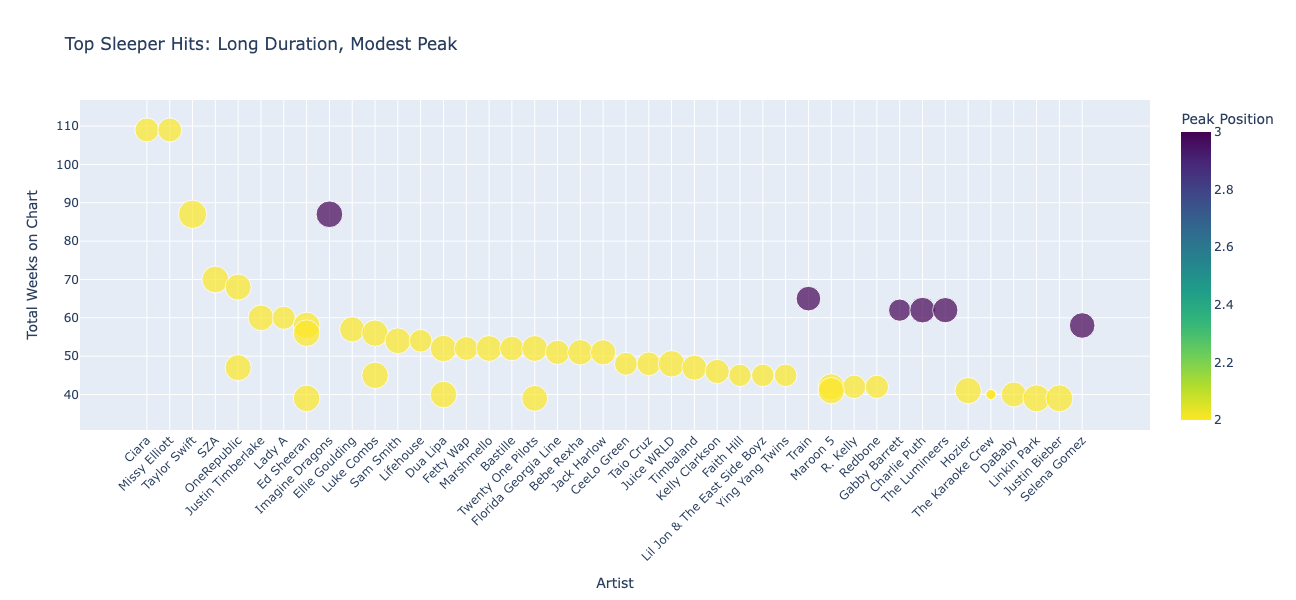

In [108]:
# Take top 50 sleeper hits
top_sleepers_display = final_sleepers_display.head(50).copy()

# Ensure numeric types
top_sleepers_display['popularity'] = pd.to_numeric(top_sleepers_display['popularity'], errors='coerce')
top_sleepers_display['total_weeks'] = pd.to_numeric(top_sleepers_display['total_weeks'], errors='coerce')
top_sleepers_display['peak_position'] = pd.to_numeric(top_sleepers_display['peak_position'], errors='coerce')

# Bubble chart
fig = px.scatter(
    top_sleepers_display,
    x='name',
    y='total_weeks',
    size='popularity',          # now numeric
    color='peak_position',      # numeric
    hover_data=['track_name', 'sleeper_score', 'popularity', 'followers'],
    color_continuous_scale='Viridis_r',  # darker = better peak
    title='Top Sleeper Hits: Long Duration, Modest Peak',
    labels={
        'name': 'Artist',
        'total_weeks': 'Total Weeks on Chart',
        'peak_position': 'Peak Position',
        'popularity': 'Popularity'
    },
    height=600
)

fig.update_layout(
    xaxis_tickangle=-45
)

fig.show()

#### 3.4 Top 50 Sleeper Hits – Insight & Key Takeaway

- **Chart duration vs peak:** Tracks spend 40–100+ weeks with modest peaks around #2–3 (e.g., *1, 2 Step* – 109 wks, peak 2; *You Belong With Me* – 87 wks, peak 2) 
- **Sleeper scores:** Measure longevity relative to peak (e.g., *1, 2 Step* – 54.5; *You Belong With Me* – 43.5; *Snooze* – 35.0)  
- **Repeat performers:** Ed Sheeran, Taylor Swift, Dua Lipa, Maroon 5, OneRepublic consistently dominate  
- **Collaborations:** Tracks like *1, 2 Step*, *Levitating*, *Meant to Be* combine fanbases, boosting chart life  
- **Lesser-known artists:** The Karaoke Crew, Gabby Barrett show that **broad appeal can outweigh follower count**  

**Insight:**  
Sleeper hits thrive on **steady engagement, repeat listening, and consistent audience appeal**, rather than instant peak performance.  

**Key Takeaway:**  
Long-term chart success is built on **longevity and sustained fan connection**, proving that tracks can achieve enduring relevance without ever hitting #1.

### Layer 3: Takeaway – Spotlight the Heroes

Layer 3 highlights the **tracks and artists that quietly dominate the Hot 100 through longevity and consistent engagement**.  

- **Longest-charting hidden champions** are mostly single-artist tracks with moderate to high popularity, spanning both classic and modern hits.  
- **Top-performing artists** like Drake, Taylor Swift, and Ariana Grande consistently produce hidden longevity champions, while niche performers can also achieve notable endurance.  
- **Re-charting and evergreen tracks** demonstrate that timeless appeal and seasonal resurgence extend chart presence well beyond the initial release.  
- **Sleeper hits** show that tracks with modest peak positions can remain relevant for years through repeat listening and broad audience appeal.  

**Bottom line:** Long-term Hot 100 success is driven by **steady audience engagement, repeatability, and perennial relevance**, proving that chart longevity often comes from consistent resonance rather than headline-grabbing peaks.

# Final Takeaway – The Hidden Heroes of the Hot 100

Not every hit needs to grab the #1 spot to make history. Some songs quietly linger on the charts for weeks, months, even years, building what we call the **hidden longevity champions** of the Hot 100. These tracks may not dominate headlines, but their staying power tells a story about what listeners really connect with.  

Many of these champions come from **full albums** and are **clean, radio-friendly tracks**. They often clock in at a **sweet spot of around 3–4 minutes**, with just the right mix of danceability, energy, and tempo to keep listeners coming back. Peak positions rarely tell the full story—**#2 or #3 is often enough** to build weeks of steady chart presence.  

The artists behind these songs are a mix of the familiar and the unexpected. **Drake, Taylor Swift, and Ariana Grande** repeatedly appear, proving that consistent output and a loyal fanbase sustain long-term success. Yet, niche acts and lesser-known performers also make their mark, showing that **broad appeal and repeat listening can outweigh fame alone**.  

Some tracks return year after year, especially **holiday and evergreen songs**, highlighting that **timelessness and seasonal resurgence** can keep a song alive across decades. Others are **sleeper hits**, modest at first glance but quietly building momentum week by week—songs like *1, 2 Step* or *You Belong With Me* demonstrate that **longevity often trumps instant stardom**.  

**Bottom line:** The Hot 100 rewards more than flash—it rewards songs and artists that resonate, endure, and keep listeners coming back. True chart heroes aren’t always the ones at the top; they’re the ones who **stay**, quietly shaping the soundtrack of generations.